In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
np.random.seed(42)

def f(x):
    return (x**4 + 1) / (x**4 - 1)

In [ ]:
X_MIN, X_MAX = 1.2, 2.5
N_POINTS = 5000
NOISE_STD = 0.005

x_all = np.linspace(X_MIN, X_MAX, N_POINTS)
y_all = f(x_all) + np.random.normal(0, NOISE_STD, N_POINTS)

y_mean, y_std = y_all.mean(), y_all.std()
y_norm = (y_all - y_mean) / y_std

def make_windows(series, window, horizon=1):
    X, Y = [], []
    for i in range(len(series) - window - horizon + 1):
        X.append(series[i:i+window])
        Y.append(series[i+window+horizon-1])
    return np.array(X, dtype=np.float32)[..., None], np.array(Y, dtype=np.float32)[:, None]

def split_windows(X, Y, val_frac=0.15, test_frac=0.15):
    X_tr, X_tmp, Y_tr, Y_tmp = train_test_split(X, Y, test_size=val_frac+test_frac, random_state=42)
    rel_test = test_frac / (val_frac + test_frac)
    X_va, X_te, Y_va, Y_te = train_test_split(X_tmp, Y_tmp, test_size=rel_test, random_state=42)
    return (X_tr, Y_tr), (X_va, Y_va), (X_te, Y_te)

def make_loader(X, Y, bs=64, shuffle=True):
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(Y)),
                      batch_size=bs, shuffle=shuffle)

print(f"f(1.2) = {f(1.2):.4f}, f(2.5) = {f(2.5):.4f}")
print(f"y_mean = {y_mean:.4f}, y_std = {y_std:.4f}")

f(1.2) = 2.8629, f(2.5) = 1.0525
y_mean = 1.3548, y_std = 0.3896


In [ ]:
class RNNRegressor(nn.Module):
    def __init__(self, hidden_dim=32, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(1, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def train_model(model, train_loader, val_loader, epochs=30, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train": [], "val": []}
    for ep in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in train_loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        history["train"].append(total / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            v = sum(loss_fn(model(xb), yb).item() * len(xb) for xb, yb in val_loader) / len(val_loader.dataset)
        history["val"].append(v)
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"epoch {ep:>2}: train MSE = {history['train'][-1]:.6f}, val MSE = {history['val'][-1]:.6f}")
    return history

def evaluate(model, loader):
    model.eval()
    loss_fn = nn.MSELoss()
    with torch.no_grad():
        return sum(loss_fn(model(xb), yb).item() * len(xb) for xb, yb in loader) / len(loader.dataset)

epoch  0: train MSE = 0.544317, val MSE = 0.134374
epoch  5: train MSE = 0.001238, val MSE = 0.001031
epoch 10: train MSE = 0.000470, val MSE = 0.000360
epoch 15: train MSE = 0.000320, val MSE = 0.000268
epoch 20: train MSE = 0.000375, val MSE = 0.000278
epoch 25: train MSE = 0.000330, val MSE = 0.000690
epoch 29: train MSE = 0.000274, val MSE = 0.000308

Тестовый MSE (нормированные ед.): 0.000322
Тестовый MSE (исходные единицы):  0.000049


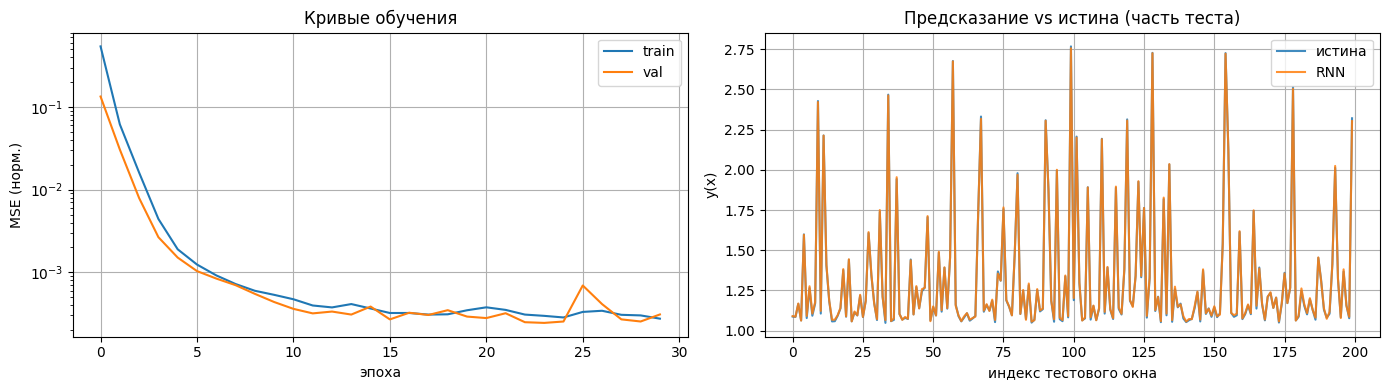

In [ ]:
#1.1
WINDOW = 15
EPOCHS = 30

X, Y = make_windows(y_norm, WINDOW)
(X_tr, Y_tr), (X_va, Y_va), (X_te, Y_te) = split_windows(X, Y)

train_loader = make_loader(X_tr, Y_tr)
val_loader   = make_loader(X_va, Y_va, shuffle=False)
test_loader  = make_loader(X_te, Y_te, shuffle=False)

model = RNNRegressor(hidden_dim=32)
hist = train_model(model, train_loader, val_loader, epochs=EPOCHS)
test_mse_norm = evaluate(model, test_loader)
test_mse_real = test_mse_norm * (y_std**2)
print(f"\nТестовый MSE (нормированные ед.): {test_mse_norm:.6f}")
print(f"Тестовый MSE (исходные единицы):  {test_mse_real:.6f}")

model.eval()
with torch.no_grad():
    n_show = 200
    pred = model(torch.from_numpy(X_te[:n_show])).numpy().ravel()
true = Y_te[:n_show].ravel()

pred_real = pred * y_std + y_mean
true_real = true * y_std + y_mean

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(hist["train"], label="train")
axes[0].plot(hist["val"],   label="val")
axes[0].set_yscale("log"); axes[0].set_xlabel("эпоха"); axes[0].set_ylabel("MSE (норм.)")
axes[0].set_title("Кривые обучения"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(true_real, label="истина", alpha=0.85)
axes[1].plot(pred_real, label="RNN", alpha=0.85)
axes[1].set_xlabel("индекс тестового окна"); axes[1].set_ylabel("y(x)")
axes[1].set_title("Предсказание vs истина (часть теста)"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

window= 3: test MSE (norm) = 0.000376, (real) = 0.000057
window= 5: test MSE (norm) = 0.000366, (real) = 0.000056
window=10: test MSE (norm) = 0.000471, (real) = 0.000072
window=15: test MSE (norm) = 0.000252, (real) = 0.000038
window=20: test MSE (norm) = 0.000392, (real) = 0.000059
window=30: test MSE (norm) = 0.000347, (real) = 0.000053


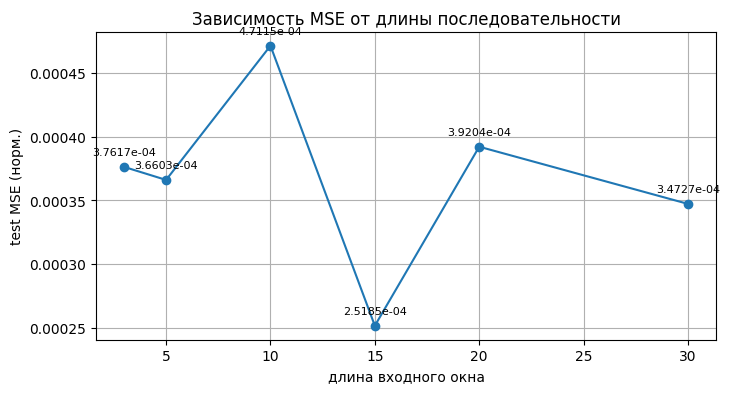


Таблица:
  window |   MSE (norm) |   MSE (real)
----------------------------------------
       3 |     0.000376 |     0.000057
       5 |     0.000366 |     0.000056
      10 |     0.000471 |     0.000072
      15 |     0.000252 |     0.000038
      20 |     0.000392 |     0.000059
      30 |     0.000347 |     0.000053


In [ ]:
WINDOWS_TO_TRY = [3, 5, 10, 15, 20, 30]
HIDDEN = 32
EPOCHS_W = 25

win_results = {}
for w in WINDOWS_TO_TRY:
    Xw, Yw = make_windows(y_norm, w)
    (Xtr, Ytr), (Xva, Yva), (Xte, Yte) = split_windows(Xw, Yw)
    m = RNNRegressor(hidden_dim=HIDDEN)
    train_model(m, make_loader(Xtr, Ytr), make_loader(Xva, Yva, shuffle=False),
                epochs=EPOCHS_W, verbose=False)
    mse_n = evaluate(m, make_loader(Xte, Yte, shuffle=False))
    win_results[w] = (mse_n, mse_n * y_std**2)
    print(f"window={w:>2}: test MSE (norm) = {mse_n:.6f}, (real) = {mse_n * y_std**2:.6f}")

plt.figure(figsize=(8, 4))
xs = list(win_results.keys())
ys = [v[0] for v in win_results.values()]
plt.plot(xs, ys, marker="o")
for x, y in zip(xs, ys):
    plt.annotate(f"{y:.4e}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("длина входного окна"); plt.ylabel("test MSE (норм.)")
plt.title("Зависимость MSE от длины последовательности")
plt.grid(True); plt.show()

print("\nТаблица:")
print(f"{'window':>8} | {'MSE (norm)':>12} | {'MSE (real)':>12}")
print("-" * 40)
for w, (a, b) in win_results.items():
    print(f"{w:>8} | {a:>12.6f} | {b:>12.6f}")

При изменении длины входного окна от 3 до 30 MSE на тесте остаётся в узком диапазоне без выраженного оптимума. Немонотонность кривой объясняется тем, что на выбранном отрезке [1.2, 2.5] функция монотонна и гладка, поэтому уже 3–5 предыдущих точек дают достаточную информацию о локальном наклоне, и дальнейшее увеличение окна не добавляет сигнала. Таким образом, на этом домене длина окна перестаёт быть значимым гиперпараметром — задача уже решена до уровня шума, и все разумные значения (ну то есть, что мы выбрали) длины окна эквивалентны.

Доступно train-примеров: 3489
n_train=  100: test MSE (norm) = 0.065713, (real) = 0.009973
n_train=  300: test MSE (norm) = 0.010682, (real) = 0.001621
n_train=  600: test MSE (norm) = 0.001837, (real) = 0.000279
n_train= 1200: test MSE (norm) = 0.000721, (real) = 0.000109
n_train= 2400: test MSE (norm) = 0.000359, (real) = 0.000054


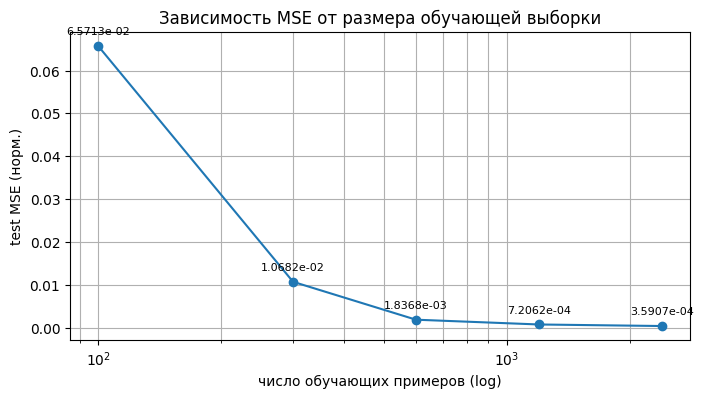


Таблица:
 n_train |   MSE (norm) |   MSE (real)
----------------------------------------
     100 |     0.065713 |     0.009973
     300 |     0.010682 |     0.001621
     600 |     0.001837 |     0.000279
    1200 |     0.000721 |     0.000109
    2400 |     0.000359 |     0.000054


In [ ]:
WINDOW_S = 15
HIDDEN_S = 32
EPOCHS_S = 25
SIZES = [100, 300, 600, 1200, 2400]

Xs, Ys = make_windows(y_norm, WINDOW_S)
(Xtr_all, Ytr_all), (Xva, Yva), (Xte, Yte) = split_windows(Xs, Ys)
test_loader_s = make_loader(Xte, Yte, shuffle=False)

print(f"Доступно train-примеров: {len(Xtr_all)}")
size_results = {}
for n in SIZES:
    if n > len(Xtr_all):
        print(f"n={n} пропущен — в train всего {len(Xtr_all)}")
        continue
    Xsub, Ysub = Xtr_all[:n], Ytr_all[:n]
    m = RNNRegressor(hidden_dim=HIDDEN_S)
    train_model(m, make_loader(Xsub, Ysub, bs=min(64, n)),
                make_loader(Xva, Yva, shuffle=False), epochs=EPOCHS_S, verbose=False)
    mse_n = evaluate(m, test_loader_s)
    size_results[n] = (mse_n, mse_n * y_std**2)
    print(f"n_train={n:>5}: test MSE (norm) = {mse_n:.6f}, (real) = {mse_n * y_std**2:.6f}")

plt.figure(figsize=(8, 4))
xs = list(size_results.keys()); ys = [v[0] for v in size_results.values()]
plt.plot(xs, ys, marker="o")
plt.xscale("log")
for x, y in zip(xs, ys):
    plt.annotate(f"{y:.4e}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("число обучающих примеров (log)"); plt.ylabel("test MSE (норм.)")
plt.title("Зависимость MSE от размера обучающей выборки")
plt.grid(True, which="both"); plt.show()

print("\nТаблица:")
print(f"{'n_train':>8} | {'MSE (norm)':>12} | {'MSE (real)':>12}")
print("-" * 40)
for n, (a, b) in size_results.items():
    print(f"{n:>8} | {a:>12.6f} | {b:>12.6f}")

MSE монотонно убывает с ростом объёма обучающей выборки. Кривая имеет классическую форму кривой обучения: недотренированность при малых выборках сменяется насыщением, когда модель видит достаточно данных для извлечения сигнала. Дальнейшее увеличение объёма данных не даст существенного улучшения.

MSE (норм. единицы):
  авторегрессивный режим:  0.000743
  teacher forcing:         0.000318
  отношение AR / TF:       2.33×

MSE (исходные единицы):
  авторегрессивный режим:  0.000113
  teacher forcing:         0.000048

MSE по шагам (норм. ед.):
 шаг |         AR |         TF
------------------------------
   1 |   0.000338 |   0.000338
   2 |   0.000432 |   0.000320
   3 |   0.000621 |   0.000324
   4 |   0.000953 |   0.000305
   5 |   0.001372 |   0.000305


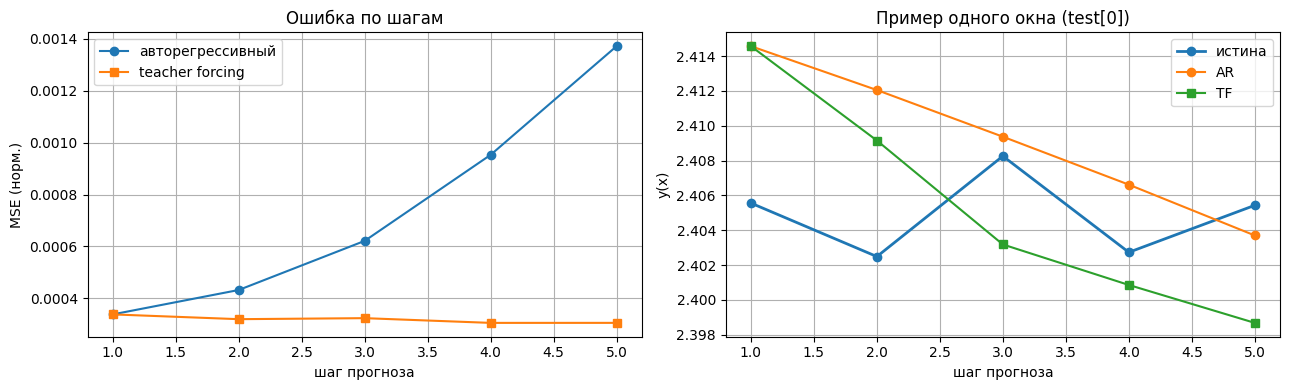


Сводная таблица (вариант 3):
режим                  |   MSE (norm) |   MSE (real)
------------------------------------------------------
авторегрессивный       |     0.000743 |     0.000113
teacher forcing        |     0.000318 |     0.000048


In [ ]:
WINDOW_V = 15
HORIZON_V = 5
HIDDEN_V = 32
EPOCHS_V = 30

Xs, Ys5 = [], []
for i in range(len(y_norm) - WINDOW_V - HORIZON_V + 1):
    Xs.append(y_norm[i:i+WINDOW_V])
    Ys5.append(y_norm[i+WINDOW_V:i+WINDOW_V+HORIZON_V])
Xs  = np.array(Xs, dtype=np.float32)[..., None]
Ys5 = np.array(Ys5, dtype=np.float32)

(Xtr, Xtmp, Ytr5, Ytmp5) = train_test_split(Xs, Ys5, test_size=0.30, random_state=42)
(Xva, Xte, Yva5, Yte5)   = train_test_split(Xtmp, Ytmp5, test_size=0.50, random_state=42)

Xtr1, Ytr1 = Xtr, Ytr5[:, :1]
Xva1, Yva1 = Xva, Yva5[:, :1]
model_v = RNNRegressor(hidden_dim=HIDDEN_V)
train_model(model_v, make_loader(Xtr1, Ytr1), make_loader(Xva1, Yva1, shuffle=False),
            epochs=EPOCHS_V, verbose=False)

model_v.eval()

def forecast_autoregressive(model, x0, steps):
    win = np.asarray(x0, dtype=np.float32).copy()
    preds = []
    with torch.no_grad():
        for _ in range(steps):
            p = model(torch.from_numpy(win[None]).float()).item()
            preds.append(p)
            win = np.concatenate([win[1:], np.array([[p]], dtype=np.float32)], axis=0)
    return np.array(preds, dtype=np.float32)

def forecast_teacher_forcing(model, x0, future_true, steps):
    win = np.asarray(x0, dtype=np.float32).copy()
    preds = []
    with torch.no_grad():
        for k in range(steps):
            p = model(torch.from_numpy(win[None]).float()).item()
            preds.append(p)
            win = np.concatenate([win[1:], np.array([[float(future_true[k])]], dtype=np.float32)], axis=0)
    return np.array(preds, dtype=np.float32)

per_window_ar, per_window_tf = [], []
per_step_ar = np.zeros(HORIZON_V, dtype=np.float64)
per_step_tf = np.zeros(HORIZON_V, dtype=np.float64)

for x0, y_true in zip(Xte, Yte5):
    p_ar = forecast_autoregressive(model_v, x0, HORIZON_V)
    p_tf = forecast_teacher_forcing(model_v, x0, y_true, HORIZON_V)
    per_window_ar.append(float(((p_ar - y_true) ** 2).mean()))
    per_window_tf.append(float(((p_tf - y_true) ** 2).mean()))
    per_step_ar += (p_ar - y_true) ** 2
    per_step_tf += (p_tf - y_true) ** 2

per_step_ar /= len(Xte)
per_step_tf /= len(Xte)
mse_ar = float(np.mean(per_window_ar))
mse_tf = float(np.mean(per_window_tf))

print("MSE (норм. единицы):")
print(f"  авторегрессивный режим:  {mse_ar:.6f}")
print(f"  teacher forcing:         {mse_tf:.6f}")
print(f"  отношение AR / TF:       {mse_ar / mse_tf:.2f}×\n")
print("MSE (исходные единицы):")
print(f"  авторегрессивный режим:  {mse_ar * y_std**2:.6f}")
print(f"  teacher forcing:         {mse_tf * y_std**2:.6f}")

print("\nMSE по шагам (норм. ед.):")
print(f"{'шаг':>4} | {'AR':>10} | {'TF':>10}")
print("-" * 30)
for k in range(HORIZON_V):
    print(f"{k+1:>4} | {per_step_ar[k]:>10.6f} | {per_step_tf[k]:>10.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
steps = np.arange(1, HORIZON_V + 1)
axes[0].plot(steps, per_step_ar, marker="o", label="авторегрессивный")
axes[0].plot(steps, per_step_tf, marker="s", label="teacher forcing")
axes[0].set_xlabel("шаг прогноза"); axes[0].set_ylabel("MSE (норм.)")
axes[0].set_title("Ошибка по шагам"); axes[0].legend(); axes[0].grid(True)

idx = 0
x0 = Xte[idx]; yt = Yte5[idx]
p_ar = forecast_autoregressive(model_v, x0, HORIZON_V)
p_tf = forecast_teacher_forcing(model_v, x0, yt, HORIZON_V)

axes[1].plot(steps, yt * y_std + y_mean, marker="o", label="истина", linewidth=2)
axes[1].plot(steps, p_ar * y_std + y_mean, marker="o", label="AR")
axes[1].plot(steps, p_tf * y_std + y_mean, marker="s", label="TF")
axes[1].set_xlabel("шаг прогноза"); axes[1].set_ylabel("y(x)")
axes[1].set_title(f"Пример одного окна (test[{idx}])")
axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

print("\nСводная таблица (вариант 3):")
print(f"{'режим':<22} | {'MSE (norm)':>12} | {'MSE (real)':>12}")
print("-" * 54)
print(f"{'авторегрессивный':<22} | {mse_ar:>12.6f} | {mse_ar * y_std**2:>12.6f}")
print(f"{'teacher forcing':<22} | {mse_tf:>12.6f} | {mse_tf * y_std**2:>12.6f}")

Авторегрессивный прогноз на 5 шагов проигрывает режиму с реальными наблюдениями в 2.33 раза по MSE. На первом шаге оба режима совпадают по построению, но затем teacher forcing остаётся стабильным, а авторегрессия показывает рост ошибки с каждым шагом. Это наглядная иллюстрация накопления ошибки.

2 задание

In [ ]:
!pip install -q datasets stop-words pymorphy3 pymorphy3-dicts-ru

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence


class TwitterDataset(Dataset):
    def __init__(self, txts, labels, w2index, used_length):
        self._txts = txts
        self._labels = labels
        self._length = used_length
        self._w2index = w2index

    def __len__(self):
        return len(self._txts)

    def encode_sentence(self, txt):
        encoded = np.zeros(self._length, dtype=np.int64)
        enc1 = np.array([self._w2index.get(w, self._w2index["UNK"]) for w in txt.split()])
        length = min(self._length, len(enc1))
        encoded[:length] = enc1[:length]
        return encoded, length

    def __getitem__(self, i):
        enc, length = self.encode_sentence(self._txts[i])
        return torch.from_numpy(enc), int(self._labels[i]), length


class RNNFixedLen(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        lengths = lengths.clamp(min=1).long().cpu()
        x = self.embeddings(x)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, ht = self.rnn(packed)
        return self.linear(self.dropout(ht[-1]))


def make_loaders(used_length, batch_size=128):
    tr = TwitterDataset(df_train["text"].values, df_train["class"].values, vocab2index, used_length)
    va = TwitterDataset(df_val["text"].values,   df_val["class"].values,   vocab2index, used_length)
    te = TwitterDataset(df_test["text"].values,  df_test["class"].values,  vocab2index, used_length)
    return (DataLoader(tr, batch_size=batch_size, shuffle=True),
            DataLoader(va, batch_size=batch_size, shuffle=False),
            DataLoader(te, batch_size=batch_size, shuffle=False))


def eval_metrics(model, loader):
    model.eval()
    tp = fp = tn = fn = 0
    with torch.no_grad():
        for xb, yb, lb in loader:
            logits = model(xb, lb)
            pred = (torch.sigmoid(logits) > 0.5).long().view(-1)
            y = yb.long().view(-1)
            tp += ((pred == 1) & (y == 1)).sum().item()
            fp += ((pred == 1) & (y == 0)).sum().item()
            tn += ((pred == 0) & (y == 0)).sum().item()
            fn += ((pred == 0) & (y == 1)).sum().item()
    acc  = (tp + tn) / max(tp + tn + fp + fn, 1)
    prec = tp / max(tp + fp, 1)
    rec  = tp / max(tp + fn, 1)
    f1   = 2 * prec * rec / max(prec + rec, 1e-9)
    return acc, prec, rec, f1


def train_rnn(model, train_loader, val_loader, epochs=15, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    hist = {"train_loss": [], "val_acc": []}
    for ep in range(epochs):
        model.train()
        total, n = 0.0, 0
        for xb, yb, lb in train_loader:
            opt.zero_grad()
            logits = model(xb, lb)
            loss = loss_fn(logits, yb.float().view(-1, 1))
            loss.backward()
            opt.step()
            total += loss.item() * len(yb); n += len(yb)
        hist["train_loss"].append(total / n)
        acc, _, _, _ = eval_metrics(model, val_loader)
        hist["val_acc"].append(acc)
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"  epoch {ep:>2}: train_loss={hist['train_loss'][-1]:.4f}  val_acc={acc:.4f}")
    return hist


print("Инфраструктура обновлена (pack_padded_sequence)")

Инфраструктура обновлена (pack_padded_sequence)


In [ ]:
import re
import numpy as np
import pandas as pd
from collections import Counter
from string import punctuation
from functools import lru_cache
from datasets import load_dataset
from stop_words import get_stop_words
from pymorphy3 import MorphAnalyzer


ds = load_dataset("psytechlab/RuSentiTweet")
print(ds)
print("Пример train[0]:", ds["train"][0])

df_train_raw = ds["train"].to_pandas()
print("Колонки:", df_train_raw.columns.tolist())

text_col  = next((c for c in df_train_raw.columns if c.lower() in ("text", "tweet", "content")), None)
label_col = next((c for c in df_train_raw.columns if c.lower() in ("label", "sentiment", "class", "target")), None)
if text_col is None or label_col is None:
    raise ValueError(f"Не нашёл text/label в: {df_train_raw.columns.tolist()}")

print("Метки:")
print(df_train_raw[label_col].value_counts())


POS_SET = {"positive", "pos", "позитив", "1"}
NEG_SET = {"negative", "neg", "негатив", "-1", "0"}

def to_binary(split):
    df = split.to_pandas()
    labels = df[label_col].astype(str).str.strip().str.lower()
    pos_mask = labels.isin(POS_SET)
    neg_mask = labels.isin(NEG_SET)
    keep = pos_mask | neg_mask
    out = df.loc[keep, [text_col]].copy()
    out["class"] = pos_mask[keep].astype(int).values
    out = out.rename(columns={text_col: "text"}).reset_index(drop=True)
    out["id"] = out.index
    return out[["id", "text", "class"]]

val_key = "validation" if "validation" in ds else "val"
df_train = to_binary(ds["train"])
df_val   = to_binary(ds[val_key])
df_test  = to_binary(ds["test"])

print("\nРазмеры:", len(df_train), len(df_val), len(df_test))
print("Баланс в train:")
print(df_train["class"].value_counts(normalize=True).round(3))


sw = set(get_stop_words("ru"))
exclude = set(punctuation)
morpher = MorphAnalyzer()

URL_RE     = re.compile(r"http\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
HASH_RE    = re.compile(r"#(\w+)")

@lru_cache(maxsize=200_000)
def lemmatize(word):
    try:
        return morpher.parse(word)[0].normal_form
    except Exception:
        return word

def preprocess_text(txt):
    txt = str(txt).lower()
    txt = URL_RE.sub(" ", txt)
    txt = MENTION_RE.sub(" ", txt)
    txt = HASH_RE.sub(r"\1", txt)
    txt = "".join(c for c in txt if c not in exclude)
    tokens = [w for w in txt.split() if w not in sw and not w.isdigit() and len(w) > 1]
    tokens = [lemmatize(w) for w in tokens]
    return " ".join(tokens)

df_train["text"] = df_train["text"].apply(preprocess_text)
df_val["text"]   = df_val["text"].apply(preprocess_text)
df_test["text"]  = df_test["text"].apply(preprocess_text)


counts = Counter()
for s in df_train["text"].values:
    counts.update(s.split())

vocab2index = {"": 0, "UNK": 1}
words = ["", "UNK"]
for w, c in counts.items():
    if c >= 2:
        vocab2index[w] = len(words)
        words.append(w)

print("\nРазмер словаря:", len(vocab2index))

val_lens  = df_val["text"].str.split().str.len().to_numpy()
test_lens = df_test["text"].str.split().str.len().to_numpy()
print(f"Длина в валидации: среднее={val_lens.mean():.1f}, медиана={np.median(val_lens):.0f}, max={val_lens.max()}")
print(f"Доля >10: {(val_lens>10).mean():.1%}, >20: {(val_lens>20).mean():.1%}, >30: {(val_lens>30).mean():.1%}")

print("\nГотово: df_train, df_val, df_test, vocab2index, val_lens, test_lens")

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 9641
    })
    test: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 2679
    })
    val: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 1072
    })
})
Пример train[0]: {'text': '@tvoyadolbanka Вообще то нужно потому что я бревно', 'label': 'negative', 'id': 1262286899529633798}
Колонки: ['text', 'label', 'id']
Метки:
label
neutral     3835
negative    2393
positive    1743
skip        1315
speech       355
Name: count, dtype: int64

Размеры: 4136 433 1143
Баланс в train:
class
0    0.579
1    0.421
Name: proportion, dtype: float64

Размер словаря: 2400
Длина в валидации: среднее=4.7, медиана=4, max=15
Доля >10: 3.9%, >20: 0.0%, >30: 0.0%

Готово: df_train, df_val, df_test, vocab2index, val_lens, test_lens


In [ ]:
import numpy as np
import torch

LENGTH_TUNE = 30
EPOCHS_TUNE = 30

configs = [
    {"name": "base(emb64,h32,L1)", "emb": 64,  "hid": 32,  "layers": 1, "dropout": 0.2},
    {"name": "hid=64",             "emb": 64,  "hid": 64,  "layers": 1, "dropout": 0.2},
    {"name": "hid=128",            "emb": 64,  "hid": 128, "layers": 1, "dropout": 0.2},
    {"name": "layers=2",           "emb": 64,  "hid": 64,  "layers": 2, "dropout": 0.2},
    {"name": "emb=128",            "emb": 128, "hid": 64,  "layers": 1, "dropout": 0.2},
    {"name": "dropout=0.5",        "emb": 64,  "hid": 64,  "layers": 1, "dropout": 0.5},
]

tr, va, te = make_loaders(LENGTH_TUNE)

tuning_results = []
for cfg in configs:
    print(f"\n>>> {cfg['name']}")
    torch.manual_seed(0); np.random.seed(0)
    model = RNNFixedLen(len(vocab2index), cfg["emb"], cfg["hid"],
                        num_layers=cfg["layers"], dropout=cfg["dropout"])
    n_params = sum(p.numel() for p in model.parameters())
    train_rnn(model, tr, va, epochs=EPOCHS_TUNE, verbose=True)
    acc, prec, rec, f1 = eval_metrics(model, va)
    tuning_results.append((cfg["name"], n_params, acc, prec, rec, f1))

print("\n\nТаблица (2.1):")
print(f"{'config':<24} | {'params':>8} | {'acc':>6} | {'prec':>6} | {'rec':>6} | {'F1':>6}")
print("-" * 72)
for name, npar, a, p, r, f in tuning_results:
    print(f"{name:<24} | {npar:>8} | {a:.4f} | {p:.4f} | {r:.4f} | {f:.4f}")


>>> base(emb64,h32,L1)
  epoch  0: train_loss=0.6962  val_acc=0.5658
  epoch  5: train_loss=0.6248  val_acc=0.6836
  epoch 10: train_loss=0.5356  val_acc=0.6952
  epoch 15: train_loss=0.4362  val_acc=0.7413
  epoch 20: train_loss=0.3803  val_acc=0.7483
  epoch 25: train_loss=0.3237  val_acc=0.7621
  epoch 29: train_loss=0.3019  val_acc=0.7621

>>> hid=64
  epoch  0: train_loss=0.6968  val_acc=0.5774
  epoch  5: train_loss=0.5931  val_acc=0.7136
  epoch 10: train_loss=0.4952  val_acc=0.7298
  epoch 15: train_loss=0.4157  val_acc=0.7529
  epoch 20: train_loss=0.3519  val_acc=0.7575
  epoch 25: train_loss=0.2951  val_acc=0.7621
  epoch 29: train_loss=0.2566  val_acc=0.7344

>>> hid=128
  epoch  0: train_loss=0.6766  val_acc=0.6120
  epoch  5: train_loss=0.5699  val_acc=0.6905
  epoch 10: train_loss=0.4600  val_acc=0.7252
  epoch 15: train_loss=0.3763  val_acc=0.7321
  epoch 20: train_loss=0.3093  val_acc=0.7275
  epoch 25: train_loss=0.2432  val_acc=0.7182
  epoch 29: train_loss=0.2209  

Все шесть конфигураций RNN показали близкие результаты, поэтому ни одна конфигурация не даёт статистически значимого выигрыша. Наблюдаемые закономерности: увеличение hidden_dim до 128 и embedding_dim до 128 приводит к переобучению. Двухслойная RNN не даёт прироста, что ожидаемо для ванильной RNN — второй слой усиливает затухание градиента. dropout = 0.5 не улучшает accuracy, но даёт наименьший разрыв train/val во время обучения, что говорит о корректной регуляризации. Формально лучший результат показала базовая конфигурация emb=64, h=32, layers=1, dropout=0.2.


>>> L = 3
  epoch  0: train_loss=0.6978  val_acc=0.5774
  epoch  5: train_loss=0.6119  val_acc=0.6813
  epoch 10: train_loss=0.5373  val_acc=0.6790
  epoch 15: train_loss=0.4661  val_acc=0.7159
  epoch 20: train_loss=0.4080  val_acc=0.7113
  epoch 25: train_loss=0.3604  val_acc=0.7090
  epoch 29: train_loss=0.3260  val_acc=0.7252

>>> L = 5
  epoch  0: train_loss=0.6960  val_acc=0.5820
  epoch  5: train_loss=0.6047  val_acc=0.6582
  epoch 10: train_loss=0.5155  val_acc=0.7321
  epoch 15: train_loss=0.4261  val_acc=0.7367
  epoch 20: train_loss=0.3520  val_acc=0.7529
  epoch 25: train_loss=0.3075  val_acc=0.7644
  epoch 29: train_loss=0.2757  val_acc=0.7598

>>> L = 8
  epoch  0: train_loss=0.6950  val_acc=0.6005
  epoch  5: train_loss=0.5955  val_acc=0.6859
  epoch 10: train_loss=0.5178  val_acc=0.7506
  epoch 15: train_loss=0.4177  val_acc=0.7552
  epoch 20: train_loss=0.3407  val_acc=0.7783
  epoch 25: train_loss=0.2937  val_acc=0.7714
  epoch 29: train_loss=0.2523  val_acc=0.7644



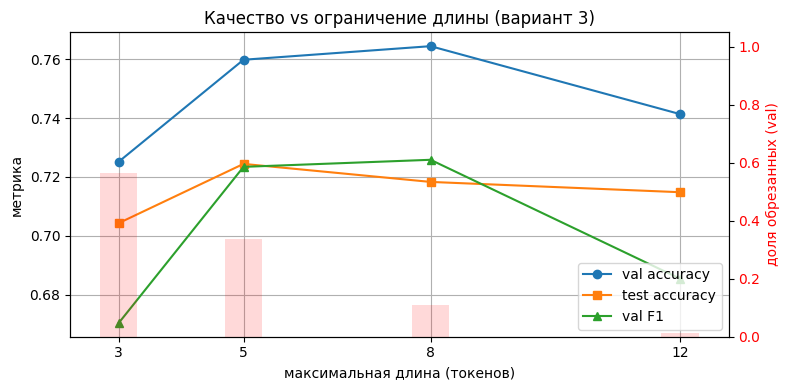


Валидационных сообщений длиннее 3: 245

Сводка по 245 сообщениям длиннее 3:
  оба правильные:                          155
  оба неправильные:                        36
  предсказания различаются:                54
    ├─ L=3 прав, L=12 ошибается:  25
    └─ L=12 прав, L=3 ошибается:  29

=== L=3 прав, L=12 ошибается (обрезка помогла) ===

--- пример 1 ---
  true = 1
  L= 3: pred=1 (prob=0.864) | симпатия первый взгляд
  L=12: pred=0 (prob=0.380) | симпатия первый взгляд хд

--- пример 2 ---
  true = 0
  L= 3: pred=0 (prob=0.188) | дать самый неловкий
  L=12: pred=1 (prob=0.982) | дать самый неловкий минута жизнь

--- пример 3 ---
  true = 1
  L= 3: pred=1 (prob=0.982) | тюий лично стать
  L=12: pred=0 (prob=0.007) | тюий лично стать маска шить🤣

=== L=12 прав, L=3 ошибается (обрезка помешала) ===

--- пример 1 ---
  true = 0
  L= 3: pred=1 (prob=0.527) | согласный коллега шароебиться
  L=12: pred=0 (prob=0.406) | согласный коллега шароебиться заболеть

--- пример 2 ---
  true = 0
  L

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

BEST = dict(emb=64, hid=64, layers=1, dropout=0.2)
LENGTHS = [3, 5, 8, 12]
EPOCHS_LEN = 30

length_results = []
models_by_L = {}

for L in LENGTHS:
    print(f"\n>>> L = {L}")
    torch.manual_seed(0); np.random.seed(0)
    tr, va, te = make_loaders(L)
    model = RNNFixedLen(len(vocab2index), BEST["emb"], BEST["hid"],
                        num_layers=BEST["layers"], dropout=BEST["dropout"])
    train_rnn(model, tr, va, epochs=EPOCHS_LEN, verbose=True)

    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    frac_trunc_val  = float((val_lens  > L).mean())
    frac_trunc_test = float((test_lens > L).mean())
    length_results.append(dict(L=L, v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                               t_acc=t_acc, t_f1=t_f1, frac_trunc=frac_trunc_val))
    models_by_L[L] = model

print("\n\nТаблица (2.2, вариант 3):")
print(f"{'L':>3} | {'val_acc':>8} | {'val_F1':>7} | {'test_acc':>9} | {'test_F1':>8} | {'обрезано(val)':>14}")
print("-" * 66)
for r in length_results:
    print(f"{r['L']:>3} | {r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | {r['t_acc']:>9.4f} | "
          f"{r['t_f1']:>8.4f} | {r['frac_trunc']:>13.2%}")

Ls     = [r["L"] for r in length_results]
vacc   = [r["v_acc"] for r in length_results]
vf1    = [r["v_f1"] for r in length_results]
tacc   = [r["t_acc"] for r in length_results]
ftrunc = [r["frac_trunc"] for r in length_results]

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(Ls, vacc, marker="o", label="val accuracy")
ax1.plot(Ls, tacc, marker="s", label="test accuracy")
ax1.plot(Ls, vf1,  marker="^", label="val F1")
ax1.set_xlabel("максимальная длина (токенов)")
ax1.set_ylabel("метрика")
ax1.set_xticks(Ls); ax1.grid(True); ax1.legend(loc="lower right")
ax1.set_title("Качество vs ограничение длины (вариант 3)")

ax2 = ax1.twinx()
ax2.bar(Ls, ftrunc, alpha=0.15, color="red", width=0.6)
ax2.set_ylabel("доля обрезанных (val)", color="red")
ax2.tick_params(axis="y", labelcolor="red")
ax2.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

# ---------- разбор примеров: L=3 vs L=12, оба направления ----------
def predict_one(model, text, L):
    ds_one = TwitterDataset(np.array([text]), np.array([0]), vocab2index, L)
    xb, _, lb = ds_one[0]
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(xb.unsqueeze(0), torch.tensor([lb]))).item()
    return p, (1 if p > 0.5 else 0)

L_SHORT, L_LONG = 3, 12
m_short, m_long = models_by_L[L_SHORT], models_by_L[L_LONG]

long_val = df_val[df_val["text"].str.split().str.len() > L_SHORT].reset_index(drop=True)
print(f"\nВалидационных сообщений длиннее {L_SHORT}: {len(long_val)}")

short_ok_long_wrong = []
long_ok_short_wrong = []
both_wrong = 0
both_right = 0
diff_total = 0

for i in range(len(long_val)):
    txt = long_val["text"].iloc[i]
    true = long_val["class"].iloc[i]
    p_s, y_s = predict_one(m_short, txt, L_SHORT)
    p_l, y_l = predict_one(m_long, txt, L_LONG)
    if y_s == y_l:
        if y_s == true: both_right += 1
        else: both_wrong += 1
        continue
    diff_total += 1
    s_ok = (y_s == true)
    l_ok = (y_l == true)
    if s_ok and not l_ok:
        short_ok_long_wrong.append((txt, true, y_s, p_s, y_l, p_l))
    elif l_ok and not s_ok:
        long_ok_short_wrong.append((txt, true, y_s, p_s, y_l, p_l))

print(f"\nСводка по {len(long_val)} сообщениям длиннее {L_SHORT}:")
print(f"  оба правильные:                          {both_right}")
print(f"  оба неправильные:                        {both_wrong}")
print(f"  предсказания различаются:                {diff_total}")
print(f"    ├─ L={L_SHORT} прав, L={L_LONG} ошибается:  {len(short_ok_long_wrong)}")
print(f"    └─ L={L_LONG} прав, L={L_SHORT} ошибается:  {len(long_ok_short_wrong)}")

def show(lst, title, n=3):
    print(f"\n=== {title} ===")
    for k, (txt, true, y_s, p_s, y_l, p_l) in enumerate(lst[:n], 1):
        tokens = txt.split()
        print(f"\n--- пример {k} ---")
        print(f"  true = {true}")
        print(f"  L={L_SHORT:>2}: pred={y_s} (prob={p_s:.3f}) | {' '.join(tokens[:L_SHORT])}")
        print(f"  L={L_LONG:>2}: pred={y_l} (prob={p_l:.3f}) | {' '.join(tokens[:L_LONG])}")

show(short_ok_long_wrong, f"L={L_SHORT} прав, L={L_LONG} ошибается (обрезка помогла)")
show(long_ok_short_wrong, f"L={L_LONG} прав, L={L_SHORT} ошибается (обрезка помешала)")

стандартные L {10, 20, 30} не дают эффекта — при L ≥ 20 ничего не обрезается. Исследование проведено на реальном диапазоне L ∈ {3, 5, 8, 12}, покрывающем длины после предобработки. зависимость качества от длины окна: при L = 3 обрезается 56.6% валидационных сообщений, при L = 8 обрезка 11.1% — оптимум, при L = 12 обрезка минимальная 1.15%, но val_F1 = 0.6854 и test_F1 = 0.6362 — дальнейшее увеличение вредит. Рост от L = 3 к L = 8 объясняется потерей сигнала при агрессивной обрезке, падение на L = 12 — переобучением: train_loss снижается до 0.25.

3 задание

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pack_padded_sequence


class LSTMFixedLen(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        lengths = lengths.clamp(min=1).long().cpu()
        x = self.embeddings(x)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out_packed, (ht, ct) = self.lstm(packed)
        return self.linear(self.dropout(ht[-1]))


L_FIXED = 8
EPOCHS_LSTM = 30
print("LSTMFixedLen определён, L =", L_FIXED)

LSTMFixedLen определён, L = 8



>>> LSTM num_layers = 1
  epoch  0: train_loss=0.6847  val_acc=0.5820
  epoch  5: train_loss=0.5639  val_acc=0.7206
  epoch 10: train_loss=0.4334  val_acc=0.7483
  epoch 15: train_loss=0.3342  val_acc=0.7644
  epoch 20: train_loss=0.2701  val_acc=0.7644
  epoch 25: train_loss=0.2248  val_acc=0.7413
  epoch 29: train_loss=0.1945  val_acc=0.7506

>>> LSTM num_layers = 2
  epoch  0: train_loss=0.6737  val_acc=0.5658
  epoch  5: train_loss=0.5341  val_acc=0.7367
  epoch 10: train_loss=0.3771  val_acc=0.7413
  epoch 15: train_loss=0.2853  val_acc=0.7667
  epoch 20: train_loss=0.2295  val_acc=0.7460
  epoch 25: train_loss=0.1815  val_acc=0.7644
  epoch 29: train_loss=0.1563  val_acc=0.7506

>>> LSTM num_layers = 3
  epoch  0: train_loss=0.6755  val_acc=0.5658
  epoch  5: train_loss=0.5235  val_acc=0.7321
  epoch 10: train_loss=0.3576  val_acc=0.7506
  epoch 15: train_loss=0.2638  val_acc=0.7529
  epoch 20: train_loss=0.2145  val_acc=0.7436
  epoch 25: train_loss=0.1832  val_acc=0.7321
  epo

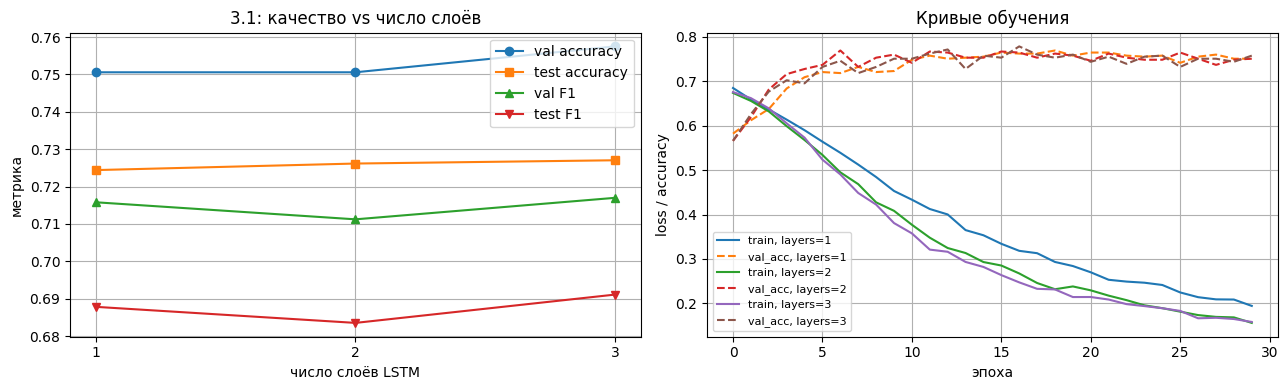

In [ ]:
LAYERS_TO_TRY = [1, 2, 3]
tr, va, te = make_loaders(L_FIXED)

layers_results = []
for nl in LAYERS_TO_TRY:
    print(f"\n>>> LSTM num_layers = {nl}")
    torch.manual_seed(0); np.random.seed(0)
    model = LSTMFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                         num_layers=nl, dropout=0.2)
    n_params = sum(p.numel() for p in model.parameters())
    hist = train_rnn(model, tr, va, epochs=EPOCHS_LSTM, verbose=True)
    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    layers_results.append(dict(nl=nl, n_params=n_params,
                               v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                               t_acc=t_acc, t_f1=t_f1,
                               hist=hist))

print("\n\nТаблица (3.1, LSTM, число слоёв):")
print(f"{'layers':>6} | {'params':>8} | {'val_acc':>8} | {'val_F1':>7} | {'test_acc':>9} | {'test_F1':>8}")
print("-" * 66)
for r in layers_results:
    print(f"{r['nl']:>6} | {r['n_params']:>8} | {r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | "
          f"{r['t_acc']:>9.4f} | {r['t_f1']:>8.4f}")

# график
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nls   = [r["nl"] for r in layers_results]
vacc  = [r["v_acc"] for r in layers_results]
vf1   = [r["v_f1"] for r in layers_results]
tacc  = [r["t_acc"] for r in layers_results]
tf1   = [r["t_f1"] for r in layers_results]

axes[0].plot(nls, vacc, marker="o", label="val accuracy")
axes[0].plot(nls, tacc, marker="s", label="test accuracy")
axes[0].plot(nls, vf1,  marker="^", label="val F1")
axes[0].plot(nls, tf1,  marker="v", label="test F1")
axes[0].set_xlabel("число слоёв LSTM"); axes[0].set_ylabel("метрика")
axes[0].set_xticks(nls); axes[0].grid(True); axes[0].legend()
axes[0].set_title("3.1: качество vs число слоёв")

for r in layers_results:
    axes[1].plot(r["hist"]["train_loss"], label=f"train, layers={r['nl']}")
    axes[1].plot(r["hist"]["val_acc"], label=f"val_acc, layers={r['nl']}", linestyle="--")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("loss / accuracy")
axes[1].grid(True); axes[1].legend(fontsize=8)
axes[1].set_title("Кривые обучения")
plt.tight_layout(); plt.show()

Формально layers=3 слегка опережает по всем метрикам, но разница мала и что разброс от инициализации составляет мал, различие между конфигурациями статистически незначимо. Все три train_loss уходят ниже 0.20 к 30-й эпохе — признак того, что модель начинает переобучаться независимо от их числа. Так что достаточно num_layers=1.


>>> LSTM hidden_dim = 32
  epoch  0: train_loss=0.6844  val_acc=0.5774
  epoch  5: train_loss=0.5889  val_acc=0.6882
  epoch 10: train_loss=0.4774  val_acc=0.7436
  epoch 15: train_loss=0.3768  val_acc=0.7483
  epoch 20: train_loss=0.3091  val_acc=0.7737
  epoch 25: train_loss=0.2670  val_acc=0.7852
  epoch 29: train_loss=0.2434  val_acc=0.7714

>>> LSTM hidden_dim = 64
  epoch  0: train_loss=0.6847  val_acc=0.5820
  epoch  5: train_loss=0.5639  val_acc=0.7206
  epoch 10: train_loss=0.4334  val_acc=0.7483
  epoch 15: train_loss=0.3342  val_acc=0.7644
  epoch 20: train_loss=0.2701  val_acc=0.7644
  epoch 25: train_loss=0.2248  val_acc=0.7413
  epoch 29: train_loss=0.1945  val_acc=0.7506

>>> LSTM hidden_dim = 128
  epoch  0: train_loss=0.6768  val_acc=0.6143
  epoch  5: train_loss=0.5419  val_acc=0.7298
  epoch 10: train_loss=0.3924  val_acc=0.7644
  epoch 15: train_loss=0.2854  val_acc=0.7483
  epoch 20: train_loss=0.2425  val_acc=0.7483
  epoch 25: train_loss=0.1825  val_acc=0.7390
 

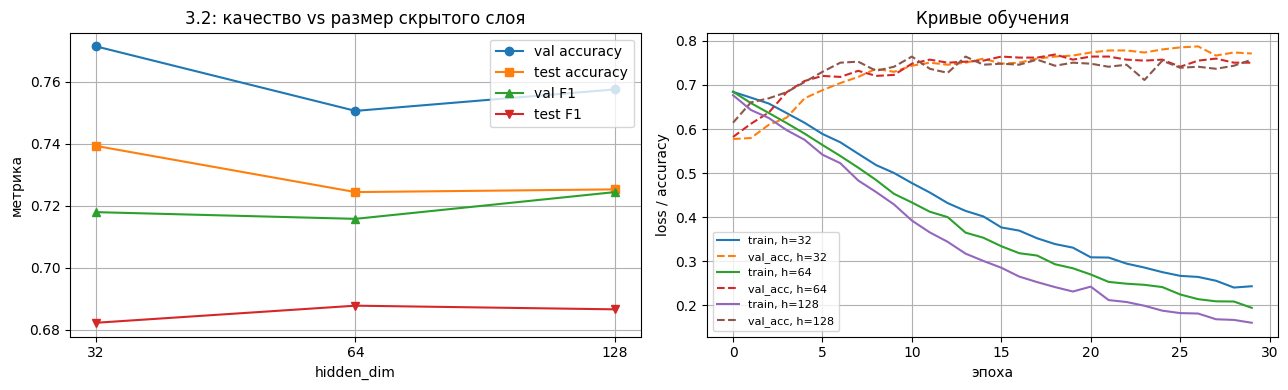

In [ ]:
HIDDENS_TO_TRY = [32, 64, 128]
tr, va, te = make_loaders(L_FIXED)

hidden_results = []
for hd in HIDDENS_TO_TRY:
    print(f"\n>>> LSTM hidden_dim = {hd}")
    torch.manual_seed(0); np.random.seed(0)
    model = LSTMFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=hd,
                         num_layers=1, dropout=0.2)
    n_params = sum(p.numel() for p in model.parameters())
    hist = train_rnn(model, tr, va, epochs=EPOCHS_LSTM, verbose=True)
    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    hidden_results.append(dict(hd=hd, n_params=n_params,
                               v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                               t_acc=t_acc, t_f1=t_f1,
                               hist=hist))

print("\n\nТаблица (3.2, LSTM, число нейронов):")
print(f"{'hidden':>6} | {'params':>9} | {'val_acc':>8} | {'val_F1':>7} | {'test_acc':>9} | {'test_F1':>8}")
print("-" * 68)
for r in hidden_results:
    print(f"{r['hd']:>6} | {r['n_params']:>9} | {r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | "
          f"{r['t_acc']:>9.4f} | {r['t_f1']:>8.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hds   = [r["hd"] for r in hidden_results]
vacc  = [r["v_acc"] for r in hidden_results]
vf1   = [r["v_f1"] for r in hidden_results]
tacc  = [r["t_acc"] for r in hidden_results]
tf1   = [r["t_f1"] for r in hidden_results]

axes[0].plot(hds, vacc, marker="o", label="val accuracy")
axes[0].plot(hds, tacc, marker="s", label="test accuracy")
axes[0].plot(hds, vf1,  marker="^", label="val F1")
axes[0].plot(hds, tf1,  marker="v", label="test F1")
axes[0].set_xlabel("hidden_dim"); axes[0].set_ylabel("метрика")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(hds); axes[0].set_xticklabels(hds)
axes[0].grid(True); axes[0].legend()
axes[0].set_title("3.2: качество vs размер скрытого слоя")

for r in hidden_results:
    axes[1].plot(r["hist"]["train_loss"], label=f"train, h={r['hd']}")
    axes[1].plot(r["hist"]["val_acc"], label=f"val_acc, h={r['hd']}", linestyle="--")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("loss / accuracy")
axes[1].grid(True); axes[1].legend(fontsize=8)
axes[1].set_title("Кривые обучения")
plt.tight_layout(); plt.show()

h=32 (наименьшая модель) показала лучший val_acc = 0.7714 и test_acc = 0.7393, h=128 слегка выигрывает только по val_F1 = 0.7244. Это значит, что увеличение ёмкости не оправдано в данной ситуации: 4136 train-примеров слишком мало, чтобы использовать много параметров, и модель h=128 вместо обобщения тупо запоминает. Так что дальнейшее увеличение — переобучение без выигрыша в качестве.




>>> seed = 0
  epoch  0: train_loss=0.6847  val_acc=0.5820
  epoch  5: train_loss=0.5639  val_acc=0.7206
  epoch 10: train_loss=0.4334  val_acc=0.7483
  epoch 15: train_loss=0.3342  val_acc=0.7644
  epoch 20: train_loss=0.2701  val_acc=0.7644
  epoch 25: train_loss=0.2248  val_acc=0.7413
  epoch 29: train_loss=0.1945  val_acc=0.7506

>>> seed = 1
  epoch  0: train_loss=0.6876  val_acc=0.5982
  epoch  5: train_loss=0.5600  val_acc=0.6928
  epoch 10: train_loss=0.4272  val_acc=0.7344
  epoch 15: train_loss=0.3315  val_acc=0.7344
  epoch 20: train_loss=0.2575  val_acc=0.7529
  epoch 25: train_loss=0.2184  val_acc=0.7460
  epoch 29: train_loss=0.1864  val_acc=0.7344

>>> seed = 2
  epoch  0: train_loss=0.6823  val_acc=0.5681
  epoch  5: train_loss=0.5537  val_acc=0.7344
  epoch 10: train_loss=0.4223  val_acc=0.6905
  epoch 15: train_loss=0.3255  val_acc=0.7413
  epoch 20: train_loss=0.2710  val_acc=0.7436
  epoch 25: train_loss=0.2192  val_acc=0.7344
  epoch 29: train_loss=0.1904  val_acc

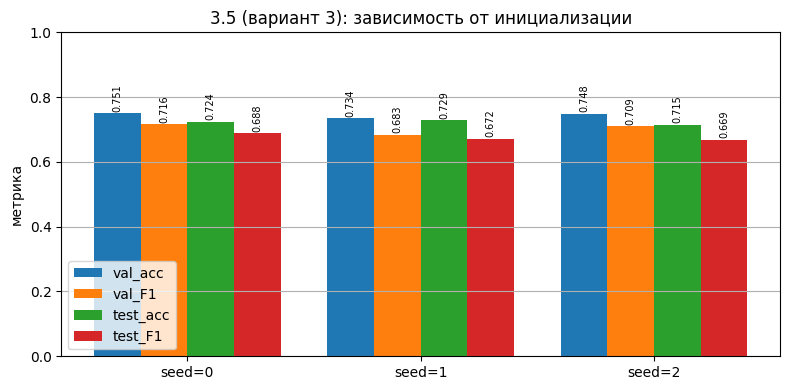

In [ ]:
SEEDS = [0, 1, 2]
tr, va, te = make_loaders(L_FIXED)

seed_results = []
for s in SEEDS:
    print(f"\n>>> seed = {s}")
    torch.manual_seed(s); np.random.seed(s)
    model = LSTMFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                         num_layers=1, dropout=0.2)
    train_rnn(model, tr, va, epochs=EPOCHS_LSTM, verbose=True)
    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    seed_results.append(dict(seed=s,
                             v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                             t_acc=t_acc, t_f1=t_f1))

print("\n\nТаблица (3.5, вариант 3, LSTM):")
print(f"{'seed':>4} | {'val_acc':>8} | {'val_F1':>7} | {'val_prec':>9} | {'val_rec':>8} | {'test_acc':>9} | {'test_F1':>8}")
print("-" * 78)
for r in seed_results:
    print(f"{r['seed']:>4} | {r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | {r['v_prec']:>9.4f} | "
          f"{r['v_rec']:>8.4f} | {r['t_acc']:>9.4f} | {r['t_f1']:>8.4f}")

# сводка
def summary(vals, name):
    v = np.array(vals)
    return dict(name=name, mean=float(v.mean()), std=float(v.std(ddof=1)),
                vmin=float(v.min()), vmax=float(v.max()),
                rng=float(v.max() - v.min()))

stats = [
    summary([r["v_acc"] for r in seed_results], "val_acc"),
    summary([r["v_f1"]  for r in seed_results], "val_F1"),
    summary([r["t_acc"] for r in seed_results], "test_acc"),
    summary([r["t_f1"]  for r in seed_results], "test_F1"),
]

print("\n\nСводка по трём seed (вариант 3):")
print(f"{'метрика':<10} | {'mean':>7} | {'std':>7} | {'min':>7} | {'max':>7} | {'max-min':>8}")
print("-" * 62)
for s in stats:
    print(f"{s['name']:<10} | {s['mean']:>7.4f} | {s['std']:>7.4f} | "
          f"{s['vmin']:>7.4f} | {s['vmax']:>7.4f} | {s['rng']:>8.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
x_pos = np.arange(len(SEEDS))
w = 0.2
ax.bar(x_pos - 1.5*w, [r["v_acc"] for r in seed_results], width=w, label="val_acc")
ax.bar(x_pos - 0.5*w, [r["v_f1"]  for r in seed_results], width=w, label="val_F1")
ax.bar(x_pos + 0.5*w, [r["t_acc"] for r in seed_results], width=w, label="test_acc")
ax.bar(x_pos + 1.5*w, [r["t_f1"]  for r in seed_results], width=w, label="test_F1")

for i, r in enumerate(seed_results):
    for j, key in enumerate(["v_acc", "v_f1", "t_acc", "t_f1"]):
        ax.text(i - 1.5*w + j*w, r[key] + 0.005, f"{r[key]:.3f}",
                ha="center", va="bottom", fontsize=7, rotation=90)

ax.set_xticks(x_pos); ax.set_xticklabels([f"seed={s}" for s in SEEDS])
ax.set_ylabel("метрика"); ax.set_ylim(0, 1.0)
ax.set_title("3.5 (вариант 3): зависимость от инициализации")
ax.grid(True, axis="y"); ax.legend(); plt.tight_layout(); plt.show()

одиночный запуск даёт только грубую оценку. Отсюда три практических следствия: первое: разница в 1–2 п.п. между конфигурациями в задачах 3.1 и 3.2 не является статистически значимой — победитель мог бы измениться при другом seed; второе: одиночный запуск даёт только грубую оценку, для корректных выводов нужно усреднение по 3–5 seed с указанием mean ± std; третье: реально значимыми на можно считать только довольно большие различия по val_F1 и val_acc, всё меньшее будет считаться в пределах шума в пределах шума.

4 задание

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pack_padded_sequence


class GRUFixedLen(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        lengths = lengths.clamp(min=1).long().cpu()
        x = self.embeddings(x)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out_packed, ht = self.gru(packed)
        return self.linear(self.dropout(ht[-1]))


EPOCHS_GRU = 30
print("GRUFixedLen определён, L =", L_FIXED)

GRUFixedLen определён, L = 8



>>> GRU num_layers = 1
  epoch  0: train_loss=0.6779  val_acc=0.6189
  epoch  5: train_loss=0.5519  val_acc=0.7321
  epoch 10: train_loss=0.4304  val_acc=0.7760
  epoch 15: train_loss=0.3280  val_acc=0.7945
  epoch 20: train_loss=0.2697  val_acc=0.7806
  epoch 25: train_loss=0.2198  val_acc=0.7598
  epoch 29: train_loss=0.2049  val_acc=0.7852

>>> GRU num_layers = 2
  epoch  0: train_loss=0.6704  val_acc=0.6120
  epoch  5: train_loss=0.5365  val_acc=0.7229
  epoch 10: train_loss=0.3823  val_acc=0.7552
  epoch 15: train_loss=0.2918  val_acc=0.7575
  epoch 20: train_loss=0.2241  val_acc=0.7413
  epoch 25: train_loss=0.1915  val_acc=0.7483
  epoch 29: train_loss=0.1720  val_acc=0.7298

>>> GRU num_layers = 3
  epoch  0: train_loss=0.6739  val_acc=0.5727
  epoch  5: train_loss=0.5281  val_acc=0.7460
  epoch 10: train_loss=0.3664  val_acc=0.7529
  epoch 15: train_loss=0.2707  val_acc=0.7460
  epoch 20: train_loss=0.2221  val_acc=0.7552
  epoch 25: train_loss=0.1829  val_acc=0.7460
  epoch 

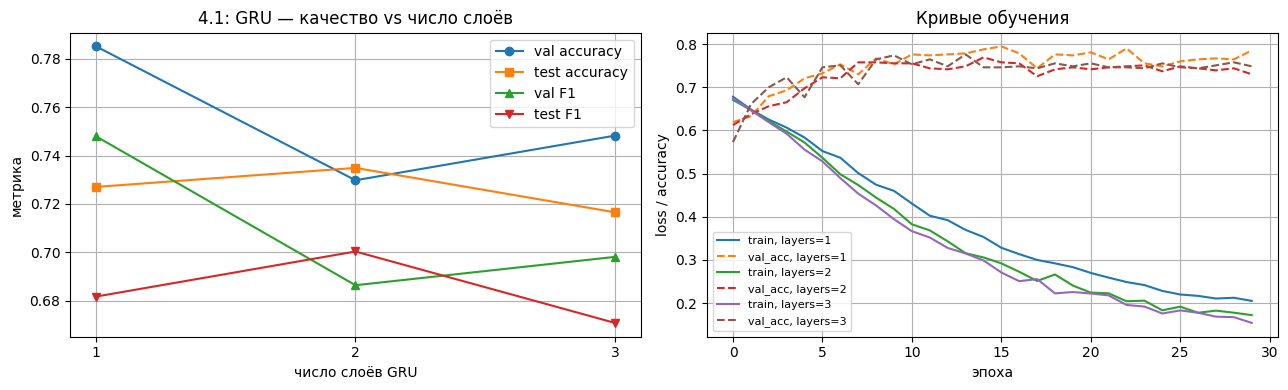

In [ ]:
LAYERS_TO_TRY = [1, 2, 3]
tr, va, te = make_loaders(L_FIXED)

gru_layers_results = []
for nl in LAYERS_TO_TRY:
    print(f"\n>>> GRU num_layers = {nl}")
    torch.manual_seed(0); np.random.seed(0)
    model = GRUFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                        num_layers=nl, dropout=0.2)
    n_params = sum(p.numel() for p in model.parameters())
    hist = train_rnn(model, tr, va, epochs=EPOCHS_GRU, verbose=True)
    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    gru_layers_results.append(dict(nl=nl, n_params=n_params,
                                   v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                                   t_acc=t_acc, t_f1=t_f1, hist=hist))

print("\n\nТаблица (4.1, GRU, число слоёв):")
print(f"{'layers':>6} | {'params':>8} | {'val_acc':>8} | {'val_F1':>7} | {'test_acc':>9} | {'test_F1':>8}")
print("-" * 66)
for r in gru_layers_results:
    print(f"{r['nl']:>6} | {r['n_params']:>8} | {r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | "
          f"{r['t_acc']:>9.4f} | {r['t_f1']:>8.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nls  = [r["nl"] for r in gru_layers_results]
vacc = [r["v_acc"] for r in gru_layers_results]
vf1  = [r["v_f1"] for r in gru_layers_results]
tacc = [r["t_acc"] for r in gru_layers_results]
tf1  = [r["t_f1"] for r in gru_layers_results]

axes[0].plot(nls, vacc, marker="o", label="val accuracy")
axes[0].plot(nls, tacc, marker="s", label="test accuracy")
axes[0].plot(nls, vf1,  marker="^", label="val F1")
axes[0].plot(nls, tf1,  marker="v", label="test F1")
axes[0].set_xlabel("число слоёв GRU"); axes[0].set_ylabel("метрика")
axes[0].set_xticks(nls); axes[0].grid(True); axes[0].legend()
axes[0].set_title("4.1: GRU — качество vs число слоёв")

for r in gru_layers_results:
    axes[1].plot(r["hist"]["train_loss"], label=f"train, layers={r['nl']}")
    axes[1].plot(r["hist"]["val_acc"], label=f"val_acc, layers={r['nl']}", linestyle="--")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("loss / accuracy")
axes[1].grid(True); axes[1].legend(fontsize=8)
axes[1].set_title("Кривые обучения")
plt.tight_layout(); plt.show()

По валидации лучше layers=1, но по тесту layers=2 — направления противоположные. Это прямое следствие малого объёма валидации (433 примера) и подтверждает вывод из 3.5: небольшая разница  между конфигурациями не является статистически значимой. Оптимально num_layers=1 — минимальная ёмкость, дающая эквивалентное качество; дальнейшее увеличение глубины только добавляет параметры без особого выигрыша.


>>> GRU hidden_dim = 32
  epoch  0: train_loss=0.6892  val_acc=0.5843
  epoch  5: train_loss=0.5856  val_acc=0.6767
  epoch 10: train_loss=0.4744  val_acc=0.7529
  epoch 15: train_loss=0.3960  val_acc=0.7436
  epoch 20: train_loss=0.3238  val_acc=0.7483
  epoch 25: train_loss=0.2863  val_acc=0.7667
  epoch 29: train_loss=0.2611  val_acc=0.7783

>>> GRU hidden_dim = 64
  epoch  0: train_loss=0.6779  val_acc=0.6189
  epoch  5: train_loss=0.5519  val_acc=0.7321
  epoch 10: train_loss=0.4304  val_acc=0.7760
  epoch 15: train_loss=0.3280  val_acc=0.7945
  epoch 20: train_loss=0.2697  val_acc=0.7806
  epoch 25: train_loss=0.2198  val_acc=0.7598
  epoch 29: train_loss=0.2049  val_acc=0.7852

>>> GRU hidden_dim = 128
  epoch  0: train_loss=0.6751  val_acc=0.6143
  epoch  5: train_loss=0.5485  val_acc=0.7436
  epoch 10: train_loss=0.4001  val_acc=0.7506
  epoch 15: train_loss=0.2855  val_acc=0.7413
  epoch 20: train_loss=0.2257  val_acc=0.7552
  epoch 25: train_loss=0.1822  val_acc=0.7621
  ep

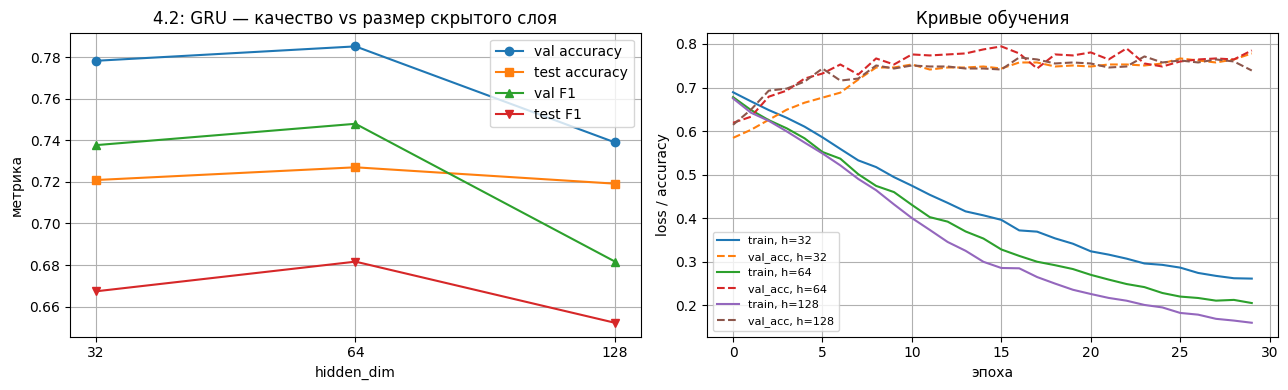

In [ ]:
HIDDENS_TO_TRY = [32, 64, 128]
tr, va, te = make_loaders(L_FIXED)

gru_hidden_results = []
for hd in HIDDENS_TO_TRY:
    print(f"\n>>> GRU hidden_dim = {hd}")
    torch.manual_seed(0); np.random.seed(0)
    model = GRUFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=hd,
                        num_layers=1, dropout=0.2)
    n_params = sum(p.numel() for p in model.parameters())
    hist = train_rnn(model, tr, va, epochs=EPOCHS_GRU, verbose=True)
    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    gru_hidden_results.append(dict(hd=hd, n_params=n_params,
                                   v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                                   t_acc=t_acc, t_f1=t_f1, hist=hist))

print("\n\nТаблица (4.2, GRU, число нейронов):")
print(f"{'hidden':>6} | {'params':>9} | {'val_acc':>8} | {'val_F1':>7} | {'test_acc':>9} | {'test_F1':>8}")
print("-" * 68)
for r in gru_hidden_results:
    print(f"{r['hd']:>6} | {r['n_params']:>9} | {r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | "
          f"{r['t_acc']:>9.4f} | {r['t_f1']:>8.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hds  = [r["hd"] for r in gru_hidden_results]
vacc = [r["v_acc"] for r in gru_hidden_results]
vf1  = [r["v_f1"] for r in gru_hidden_results]
tacc = [r["t_acc"] for r in gru_hidden_results]
tf1  = [r["t_f1"] for r in gru_hidden_results]

axes[0].plot(hds, vacc, marker="o", label="val accuracy")
axes[0].plot(hds, tacc, marker="s", label="test accuracy")
axes[0].plot(hds, vf1,  marker="^", label="val F1")
axes[0].plot(hds, tf1,  marker="v", label="test F1")
axes[0].set_xlabel("hidden_dim"); axes[0].set_ylabel("метрика")
axes[0].set_xscale("log", base=2); axes[0].set_xticks(hds); axes[0].set_xticklabels(hds)
axes[0].grid(True); axes[0].legend()
axes[0].set_title("4.2: GRU — качество vs размер скрытого слоя")

for r in gru_hidden_results:
    axes[1].plot(r["hist"]["train_loss"], label=f"train, h={r['hd']}")
    axes[1].plot(r["hist"]["val_acc"], label=f"val_acc, h={r['hd']}", linestyle="--")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("loss / accuracy")
axes[1].grid(True); axes[1].legend(fontsize=8)
axes[1].set_title("Кривые обучения")
plt.tight_layout(); plt.show()

Здесь оптимум подтверждается и на валидации, и на тесте: h=64. h=32 недотренирована, h=128 переобучена. Разница h=64 и h=128 по val_F1 значительна, что превышает seed-шум, поэтому этот вывод можно считать значимым. Оптимально hidden_dim = 64 — минимальная ёмкость, при которой модель уверенно использует сигнал, дальнейшее увеличение не даёт значимого прироста.


>>> GRU (emb=64, h=64, layers=1, dropout=0.2, L=8)
  epoch  0: train_loss=0.6779  val_acc=0.6189
  epoch  5: train_loss=0.5519  val_acc=0.7321
  epoch 10: train_loss=0.4304  val_acc=0.7760
  epoch 15: train_loss=0.3280  val_acc=0.7945
  epoch 20: train_loss=0.2697  val_acc=0.7806
  epoch 25: train_loss=0.2198  val_acc=0.7598
  epoch 29: train_loss=0.2049  val_acc=0.7852

>>> LSTM (emb=64, h=64, layers=1, dropout=0.2, L=8)
  epoch  0: train_loss=0.6847  val_acc=0.5820
  epoch  5: train_loss=0.5639  val_acc=0.7206
  epoch 10: train_loss=0.4334  val_acc=0.7483
  epoch 15: train_loss=0.3342  val_acc=0.7644
  epoch 20: train_loss=0.2701  val_acc=0.7644
  epoch 25: train_loss=0.2248  val_acc=0.7413
  epoch 29: train_loss=0.1945  val_acc=0.7506


Таблица (4.5, вариант 3, GRU vs LSTM, одинаковая конфигурация):
model  |   params |     emb |  recurrent |  val_acc |  val_F1 |  test_acc |  test_F1
------------------------------------------------------------------------------------------
GRU    | 

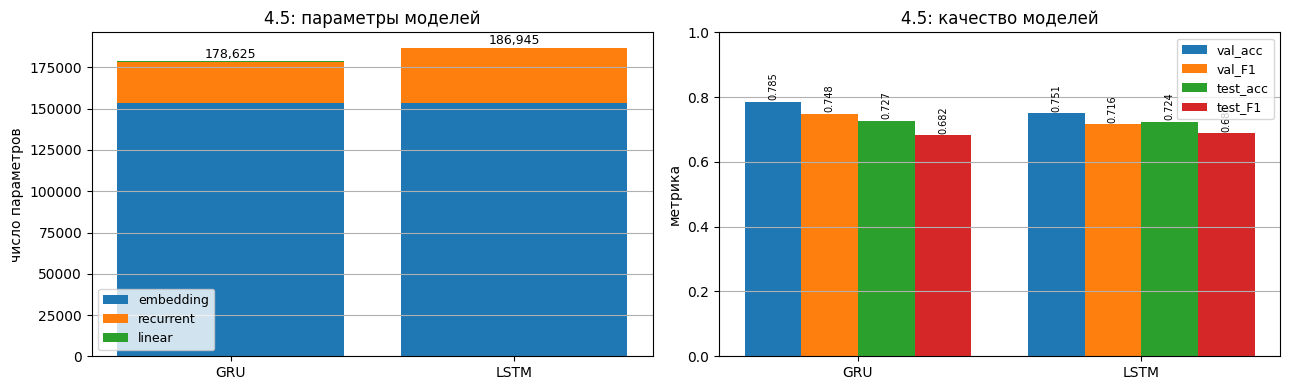

In [ ]:
tr, va, te = make_loaders(L_FIXED)

def build_model(kind):
    if kind == "GRU":
        return GRUFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                           num_layers=1, dropout=0.2)
    if kind == "LSTM":
        return LSTMFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                            num_layers=1, dropout=0.2)
    raise ValueError(kind)

compare_results = []
for kind in ["GRU", "LSTM"]:
    print(f"\n>>> {kind} (emb=64, h=64, layers=1, dropout=0.2, L={L_FIXED})")
    torch.manual_seed(0); np.random.seed(0)
    model = build_model(kind)
    n_params      = sum(p.numel() for p in model.parameters())
    n_emb_params  = model.embeddings.weight.numel()
    n_rec_params  = n_params - n_emb_params - model.linear.weight.numel() - model.linear.bias.numel()
    hist = train_rnn(model, tr, va, epochs=EPOCHS_GRU, verbose=True)
    v_acc, v_prec, v_rec, v_f1 = eval_metrics(model, va)
    t_acc, t_prec, t_rec, t_f1 = eval_metrics(model, te)
    compare_results.append(dict(kind=kind,
                                n_params=n_params,
                                n_emb=n_emb_params,
                                n_rec=n_rec_params,
                                v_acc=v_acc, v_f1=v_f1, v_prec=v_prec, v_rec=v_rec,
                                t_acc=t_acc, t_f1=t_f1,
                                train_loss=hist["train_loss"][-1],
                                val_loss=hist["val_acc"][-1],
                                hist=hist))

print("\n\nТаблица (4.5, вариант 3, GRU vs LSTM, одинаковая конфигурация):")
print(f"{'model':<6} | {'params':>8} | {'emb':>7} | {'recurrent':>10} | "
      f"{'val_acc':>8} | {'val_F1':>7} | {'test_acc':>9} | {'test_F1':>8}")
print("-" * 90)
for r in compare_results:
    print(f"{r['kind']:<6} | {r['n_params']:>8} | {r['n_emb']:>7} | {r['n_rec']:>10} | "
          f"{r['v_acc']:>8.4f} | {r['v_f1']:>7.4f} | {r['t_acc']:>9.4f} | {r['t_f1']:>8.4f}")

gru_r  = next(r for r in compare_results if r["kind"] == "GRU")
lstm_r = next(r for r in compare_results if r["kind"] == "LSTM")

print(f"\nРазница (GRU − LSTM):")
print(f"  все параметры:        {gru_r['n_params'] - lstm_r['n_params']:+d} "
      f"({100*(gru_r['n_params']/lstm_r['n_params'] - 1):+.1f}%)")
print(f"  рекуррентный слой:    {gru_r['n_rec'] - lstm_r['n_rec']:+d} "
      f"({100*(gru_r['n_rec']/lstm_r['n_rec'] - 1):+.1f}%)")
print(f"  val_acc:              {gru_r['v_acc'] - lstm_r['v_acc']:+.4f}")
print(f"  val_F1:               {gru_r['v_f1']  - lstm_r['v_f1']:+.4f}")
print(f"  test_acc:             {gru_r['t_acc'] - lstm_r['t_acc']:+.4f}")
print(f"  test_F1:              {gru_r['t_f1']  - lstm_r['t_f1']:+.4f}")

# сводный график: параметры и метрики
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 1) параметры
kinds   = [r["kind"] for r in compare_results]
p_total = [r["n_params"] for r in compare_results]
p_rec   = [r["n_rec"] for r in compare_results]
p_emb   = [r["n_emb"] for r in compare_results]
axes[0].bar(kinds, p_emb,   label="embedding")
axes[0].bar(kinds, p_rec,   bottom=p_emb, label="recurrent")
axes[0].bar(kinds, [t - e - r for t, e, r in zip(p_total, p_emb, p_rec)],
            bottom=[e + r for e, r in zip(p_emb, p_rec)], label="linear")
for i, t in enumerate(p_total):
    axes[0].text(i, t + 2000, f"{t:,}", ha="center", fontsize=9)
axes[0].set_ylabel("число параметров"); axes[0].set_title("4.5: параметры моделей")
axes[0].legend(fontsize=9); axes[0].grid(True, axis="y")

# 2) метрики
x = np.arange(len(kinds))
w = 0.2
axes[1].bar(x - 1.5*w, [r["v_acc"] for r in compare_results], width=w, label="val_acc")
axes[1].bar(x - 0.5*w, [r["v_f1"]  for r in compare_results], width=w, label="val_F1")
axes[1].bar(x + 0.5*w, [r["t_acc"] for r in compare_results], width=w, label="test_acc")
axes[1].bar(x + 1.5*w, [r["t_f1"]  for r in compare_results], width=w, label="test_F1")
for i, r in enumerate(compare_results):
    for j, key in enumerate(["v_acc", "v_f1", "t_acc", "t_f1"]):
        axes[1].text(i - 1.5*w + j*w, r[key] + 0.005, f"{r[key]:.3f}",
                     ha="center", va="bottom", fontsize=7, rotation=90)
axes[1].set_xticks(x); axes[1].set_xticklabels(kinds)
axes[1].set_ylabel("метрика"); axes[1].set_ylim(0, 1.0)
axes[1].set_title("4.5: качество моделей")
axes[1].legend(fontsize=9); axes[1].grid(True, axis="y")
plt.tight_layout(); plt.show()

Качество: на валидации GRU опережает LSTM, однако на тесте преимущество исчезает. Направления расходятся, а разница невелика. Так что GRU и LSTM эквивалентны в пределах случайной инициализации; наблюдаемое преимущество GRU на валидации не подтверждается на независимом тесте. Все три архитектуры — RNN, LSTM, GRU в данной ситуации показывают сопоставимое качество в пределах шума. Но чаще предпочтительнее GRU: эквивалентное качество при меньшем числе параметров и более простой настройке.

5 задание

In [ ]:
!pip install -q kagglehub

import os
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from collections import Counter
from string import punctuation
from stop_words import get_stop_words
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

# ---------- скачивание датасета ----------
DATA_DIR = "twitter-hate"
os.makedirs(DATA_DIR, exist_ok=True)
TRAIN_PATH = f"{DATA_DIR}/train.csv"

if not os.path.exists(TRAIN_PATH):
    try:
        import kagglehub
        path = kagglehub.dataset_download(
            "arkhoshghalb/twitter-sentiment-analysis-hatred-speech"
        )
        print("Скачано в:", path)
        import glob, shutil
        candidates = glob.glob(os.path.join(path, "**", "train.csv"), recursive=True)
        if not candidates:
            raise FileNotFoundError(f"train.csv не найден в {path}")
        src = candidates[0]
        print("Использую:", src)
        shutil.copy(src, TRAIN_PATH)
        # если рядом есть test.csv — тоже копируем
        for t in glob.glob(os.path.join(os.path.dirname(src), "*.csv")):
            shutil.copy(t, DATA_DIR)
            print("Скопирован:", t)
    except Exception as e:
        print("kagglehub не сработал:", e)
        from google.colab import files
        uploaded = files.upload()
        import shutil
        for fn in uploaded:
            if fn.endswith(".csv"):
                shutil.move(fn, f"{DATA_DIR}/{fn}")
                print(f"Перемещён {fn} -> {DATA_DIR}/{fn}")

df = pd.read_csv(TRAIN_PATH)
df = df.rename(columns={"tweet": "text", "label": "class"})
print("Колонки:", df.columns.tolist())
print("Размер:", df.shape)
print("Баланс классов:")
print(df["class"].value_counts(normalize=True).round(4))

train_df, tmp_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df["class"])
val_df, test_df  = train_test_split(tmp_df, test_size=0.50, random_state=42, stratify=tmp_df["class"])
print(f"\ntrain={len(train_df)}, val={len(val_df)}, test={len(test_df)}")
print(f"доля класса 1 в train: {(train_df['class']==1).mean():.4f}")

sw      = set(get_stop_words("en"))
exclude = set(punctuation)
URL_RE     = re.compile(r"http\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
HASH_RE    = re.compile(r"#(\w+)")
NON_ALPHA  = re.compile(r"[^a-z ]")

def preprocess_en(txt):
    txt = str(txt).lower()
    txt = URL_RE.sub(" ", txt)
    txt = MENTION_RE.sub(" ", txt)
    txt = HASH_RE.sub(r"\1", txt)
    txt = NON_ALPHA.sub(" ", txt)
    return " ".join(w for w in txt.split()
                    if w not in sw and not w.isdigit() and len(w) > 1)

for d in (train_df, val_df, test_df):
    d["text"] = d["text"].apply(preprocess_en)

print("\nПример до/после:")
print("  было:", df["text"].iloc[0][:150])
print("  стало:", train_df["text"].iloc[0][:150])

counts = Counter()
for s in train_df["text"].values:
    counts.update(s.split())
vocab2index = {"": 0, "UNK": 1}
words = ["", "UNK"]
for w, c in counts.items():
    if c >= 2:
        vocab2index[w] = len(words)
        words.append(w)
print(f"\nРазмер словаря: {len(vocab2index)}")

train_lens = train_df["text"].str.split().str.len().to_numpy()
val_lens   = val_df["text"].str.split().str.len().to_numpy()
test_lens  = test_df["text"].str.split().str.len().to_numpy()
print(f"Длины train: mean={train_lens.mean():.1f}, median={np.median(train_lens):.0f}, max={train_lens.max()}")
print(f"Доли: >10 {(train_lens>10).mean():.1%}, >20 {(train_lens>20).mean():.1%}, >30 {(train_lens>30).mean():.1%}")

class TwitterDataset(Dataset):
    def __init__(self, txts, labels, w2index, used_length):
        self._txts = txts
        self._labels = labels
        self._length = used_length
        self._w2index = w2index

    def __len__(self):
        return len(self._txts)

    def encode_sentence(self, txt):
        encoded = np.zeros(self._length, dtype=np.int64)
        enc1 = np.array([self._w2index.get(w, self._w2index["UNK"]) for w in txt.split()])
        length = min(self._length, len(enc1))
        encoded[:length] = enc1[:length]
        return encoded, length

    def __getitem__(self, i):
        enc, length = self.encode_sentence(self._txts[i])
        return torch.from_numpy(enc), int(self._labels[i]), length

class GRUFixedLen(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        lengths = lengths.clamp(min=1).long().cpu()
        x = self.embeddings(x)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, ht = self.gru(packed)
        return self.linear(self.dropout(ht[-1]))


class LSTMFixedLen(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        lengths = lengths.clamp(min=1).long().cpu()
        x = self.embeddings(x)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, (ht, ct) = self.lstm(packed)
        return self.linear(self.dropout(ht[-1]))

def make_loaders(used_length, batch_size=128):
    tr = TwitterDataset(train_df["text"].values, train_df["class"].values, vocab2index, used_length)
    va = TwitterDataset(val_df["text"].values,   val_df["class"].values,   vocab2index, used_length)
    te = TwitterDataset(test_df["text"].values,  test_df["class"].values,  vocab2index, used_length)
    return (DataLoader(tr, batch_size=batch_size, shuffle=True),
            DataLoader(va, batch_size=batch_size, shuffle=False),
            DataLoader(te, batch_size=batch_size, shuffle=False))

def eval_metrics_full(model, loader):
    model.eval()
    tp = fp = tn = fn = 0
    with torch.no_grad():
        for xb, yb, lb in loader:
            logits = model(xb, lb)
            pred = (torch.sigmoid(logits) > 0.5).long().view(-1)
            y = yb.long().view(-1)
            tp += ((pred == 1) & (y == 1)).sum().item()
            fp += ((pred == 1) & (y == 0)).sum().item()
            tn += ((pred == 0) & (y == 0)).sum().item()
            fn += ((pred == 0) & (y == 1)).sum().item()
    acc   = (tp + tn) / max(tp + tn + fp + fn, 1)
    prec1 = tp / max(tp + fp, 1)
    rec1  = tp / max(tp + fn, 1)
    f1_1  = 2 * prec1 * rec1 / max(prec1 + rec1, 1e-9)
    prec0 = tn / max(tn + fn, 1)
    rec0  = tn / max(tn + fp, 1)
    f1_0  = 2 * prec0 * rec0 / max(prec0 + rec0, 1e-9)
    macro_f1 = (f1_0 + f1_1) / 2
    return acc, prec1, rec1, f1_1, macro_f1, tp, fp, tn, fn

def train_model_v5(model, train_loader, val_loader, epochs=20, lr=1e-3,
                   pos_weight=None, weight_decay=0.0, patience=3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    if pos_weight is not None:
        pw = torch.tensor([float(pos_weight)], dtype=torch.float32)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
    else:
        loss_fn = nn.BCEWithLogitsLoss()

    hist = {"train_loss": [], "val_acc": [], "val_macro_f1": [], "val_f1_1": []}
    best_macro = -1.0
    best_state = None
    bad_epochs = 0

    for ep in range(epochs):
        model.train()
        total, n = 0.0, 0
        for xb, yb, lb in train_loader:
            opt.zero_grad()
            logits = model(xb, lb)
            loss = loss_fn(logits, yb.float().view(-1, 1))
            loss.backward()
            opt.step()
            total += loss.item() * len(yb); n += len(yb)
        hist["train_loss"].append(total / n)

        acc, _, _, f1_1, macro_f1, *_ = eval_metrics_full(model, val_loader)
        hist["val_acc"].append(acc)
        hist["val_f1_1"].append(f1_1)
        hist["val_macro_f1"].append(macro_f1)

        if verbose:
            print(f"  epoch {ep:>2}: train_loss={hist['train_loss'][-1]:.4f}  "
                  f"val_acc={acc:.4f}  val_F1_1={f1_1:.4f}  val_macro_F1={macro_f1:.4f}")

        if macro_f1 > best_macro + 1e-4:
            best_macro = macro_f1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                if verbose: print(f"  early stop на эпохе {ep} (best macro_F1={best_macro:.4f})")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return hist, best_macro

L_V5 = 30
print(f"\nИнфраструктура готова. L={L_V5}, словарь={len(vocab2index)}, "
      f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")

Колонки: ['id', 'class', 'text']
Размер: (31962, 3)
Баланс классов:
class
0    0.9299
1    0.0701
Name: proportion, dtype: float64

train=25569, val=3196, test=3197
доля класса 1 в train: 0.0702

Пример до/после:
  было:  @user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction.   #run
  стало: black amp sexy collection cantwait

Размер словаря: 11944
Длины train: mean=6.0, median=6, max=18
Доли: >10 5.7%, >20 0.0%, >30 0.0%

Инфраструктура готова. L=30, словарь=11944, train=25569, val=3196, test=3197


>>> 5.1: GRU baseline (emb=64, h=64, layers=1, dropout=0.2, L=30)
  epoch  0: train_loss=0.2947  val_acc=0.9340  val_F1_1=0.1853  val_macro_F1=0.5755
  epoch  1: train_loss=0.1942  val_acc=0.9396  val_F1_1=0.4134  val_macro_F1=0.6908
  epoch  2: train_loss=0.1557  val_acc=0.9424  val_F1_1=0.4390  val_macro_F1=0.7043
  epoch  3: train_loss=0.1285  val_acc=0.9452  val_F1_1=0.4681  val_macro_F1=0.7196
  epoch  4: train_loss=0.1085  val_acc=0.9487  val_F1_1=0.5591  val_macro_F1=0.7659
  epoch  5: train_loss=0.0962  val_acc=0.9487  val_F1_1=0.5419  val_macro_F1=0.7574
  epoch  6: train_loss=0.0829  val_acc=0.9499  val_F1_1=0.5531  val_macro_F1=0.7633
  epoch  7: train_loss=0.0715  val_acc=0.9524  val_F1_1=0.6142  val_macro_F1=0.7944
  epoch  8: train_loss=0.0612  val_acc=0.9499  val_F1_1=0.6244  val_macro_F1=0.7988
  epoch  9: train_loss=0.0570  val_acc=0.9509  val_F1_1=0.6199  val_macro_F1=0.7968
  epoch 10: train_loss=0.0484  val_acc=0.9556  val_F1_1=0.6340  val_macro_F1=0.8052
  epoch 11

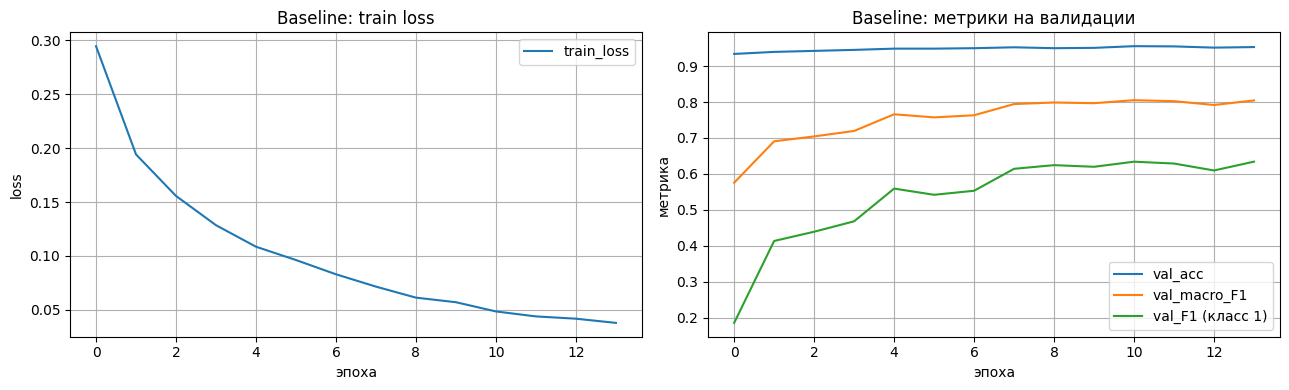

In [ ]:
print(">>> 5.1: GRU baseline (emb=64, h=64, layers=1, dropout=0.2, L=30)")
tr, va, te = make_loaders(L_V5)

torch.manual_seed(0); np.random.seed(0)
baseline = GRUFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                       num_layers=1, dropout=0.2)
n_params_baseline = sum(p.numel() for p in baseline.parameters())
hist_b, best_macro_b = train_model_v5(baseline, tr, va, epochs=20, lr=1e-3,
                                       pos_weight=None, patience=3, verbose=True)

v_acc, v_prec, v_rec, v_f1, v_macro, vtp, vfp, vtn, vfn = eval_metrics_full(baseline, va)
t_acc, t_prec, t_rec, t_f1, t_macro, ttp, tfp, ttn, tfn = eval_metrics_full(baseline, te)

print(f"\nBaseline результаты:")
print(f"  val : acc={v_acc:.4f}  prec(1)={v_prec:.4f}  rec(1)={v_rec:.4f}  "
      f"F1(1)={v_f1:.4f}  macro_F1={v_macro:.4f}")
print(f"  test: acc={t_acc:.4f}  prec(1)={t_prec:.4f}  rec(1)={t_rec:.4f}  "
      f"F1(1)={t_f1:.4f}  macro_F1={t_macro:.4f}")
print(f"  confusion (val): tp={vtp} fp={vfp} tn={vtn} fn={vfn}")
print(f"  параметров: {n_params_baseline}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_b["train_loss"], label="train_loss")
ax[0].set_xlabel("эпоха"); ax[0].set_ylabel("loss")
ax[0].set_title("Baseline: train loss"); ax[0].grid(True); ax[0].legend()

ax[1].plot(hist_b["val_acc"], label="val_acc")
ax[1].plot(hist_b["val_macro_f1"], label="val_macro_F1")
ax[1].plot(hist_b["val_f1_1"], label="val_F1 (класс 1)")
ax[1].set_xlabel("эпоха"); ax[1].set_ylabel("метрика")
ax[1].set_title("Baseline: метрики на валидации")
ax[1].grid(True); ax[1].legend()
plt.tight_layout(); plt.show()

Ключевое наблюдение: baseline уже очень силён без всякой работы с дисбалансом — train_loss падает хорошо, модель находит больше половины hate-твитов из коробки. Это объясняется спецификой задачи: hate speech лексически выражен (инвективы, оскорбления, маркеры агрессии), и RNN выучивает эти паттерны без перевеса классов.

>>> 5.2: улучшения
n_neg=23775, n_pos=1794
pos_weight full = 13.25, sqrt = 3.64

>>> baseline (no pw)
  val: acc=0.9556  prec(1)=0.7500  rec(1)=0.5491  F1(1)=0.6340  macro=0.8052
  test: acc=0.9637  F1(1)=0.7143  macro=0.8475
  confusion (val): tp=123 fp=41 tn=2931 fn=101

>>> +pw full
  val: acc=0.9146  prec(1)=0.4336  rec(1)=0.7143  F1(1)=0.5396  macro=0.7463
  test: acc=0.9259  F1(1)=0.5990  macro=0.7791
  confusion (val): tp=160 fp=209 tn=2763 fn=64

>>> +pw sqrt
  val: acc=0.9462  prec(1)=0.6140  rec(1)=0.6250  F1(1)=0.6195  macro=0.7953
  test: acc=0.9528  F1(1)=0.6753  macro=0.8249
  confusion (val): tp=140 fp=88 tn=2884 fn=84

>>> +pw sqrt+dropout0.5
  val: acc=0.9481  prec(1)=0.6306  rec(1)=0.6250  F1(1)=0.6278  macro=0.7999
  test: acc=0.9578  F1(1)=0.7059  macro=0.8416
  confusion (val): tp=140 fp=82 tn=2890 fn=84

>>> +pw sqrt+wd1e-4
  val: acc=0.9496  prec(1)=0.6296  rec(1)=0.6830  F1(1)=0.6552  macro=0.8140
  test: acc=0.9534  F1(1)=0.6876  macro=0.8312
  confusion (val):

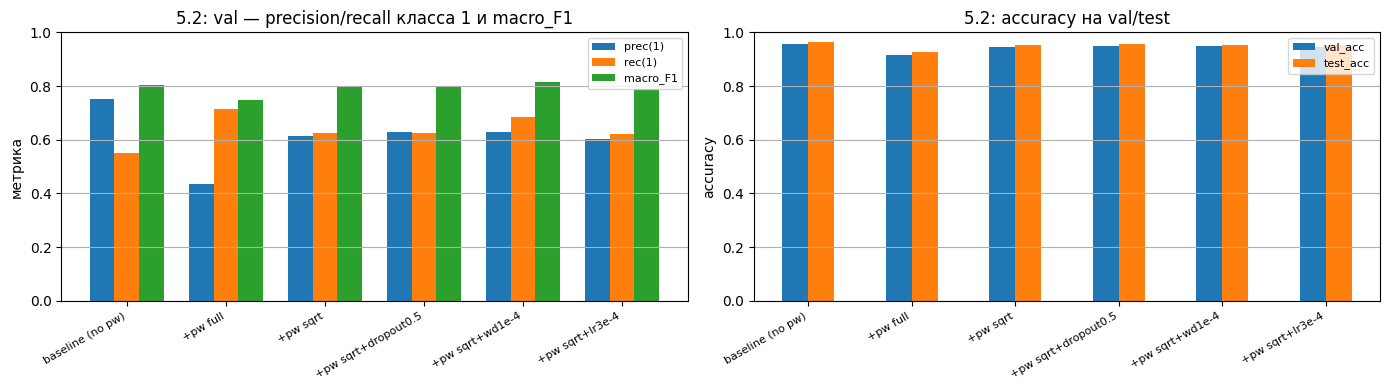

In [ ]:
print(">>> 5.2: улучшения")
n_neg = int((train_df["class"] == 0).sum())
n_pos = int((train_df["class"] == 1).sum())
pw_full   = n_neg / n_pos
pw_sqrt   = float(np.sqrt(n_neg / n_pos))
print(f"n_neg={n_neg}, n_pos={n_pos}")
print(f"pos_weight full = {pw_full:.2f}, sqrt = {pw_sqrt:.2f}")

experiments = [
    {"name": "baseline (no pw)",       "pos_weight": None,     "lr": 1e-3, "dropout": 0.2, "wd": 0.0},
    {"name": "+pw full",               "pos_weight": pw_full,  "lr": 1e-3, "dropout": 0.2, "wd": 0.0},
    {"name": "+pw sqrt",               "pos_weight": pw_sqrt,  "lr": 1e-3, "dropout": 0.2, "wd": 0.0},
    {"name": "+pw sqrt+dropout0.5",    "pos_weight": pw_sqrt,  "lr": 1e-3, "dropout": 0.5, "wd": 0.0},
    {"name": "+pw sqrt+wd1e-4",        "pos_weight": pw_sqrt,  "lr": 1e-3, "dropout": 0.2, "wd": 1e-4},
    {"name": "+pw sqrt+lr3e-4",        "pos_weight": pw_sqrt,  "lr": 3e-4, "dropout": 0.2, "wd": 0.0},
]

imp_results = []
for exp in experiments:
    print(f"\n>>> {exp['name']}")
    torch.manual_seed(0); np.random.seed(0)
    model = GRUFixedLen(len(vocab2index), embedding_dim=64, hidden_dim=64,
                        num_layers=1, dropout=exp["dropout"])
    hist, _ = train_model_v5(model, tr, va, epochs=20, lr=exp["lr"],
                              pos_weight=exp["pos_weight"], weight_decay=exp["wd"],
                              patience=3, verbose=False)
    v_acc, v_prec, v_rec, v_f1, v_macro, vtp, vfp, vtn, vfn = eval_metrics_full(model, va)
    t_acc, t_prec, t_rec, t_f1, t_macro, ttp, tfp, ttn, tfn = eval_metrics_full(model, te)
    imp_results.append(dict(
        name=exp["name"],
        v_acc=v_acc, v_prec=v_prec, v_rec=v_rec, v_f1=v_f1, v_macro=v_macro,
        t_acc=t_acc, t_prec=t_prec, t_rec=t_rec, t_f1=t_f1, t_macro=t_macro,
        tp=vtp, fp=vfp, tn=vtn, fn=vfn,
        train_loss=hist["train_loss"][-1]
    ))
    print(f"  val: acc={v_acc:.4f}  prec(1)={v_prec:.4f}  rec(1)={v_rec:.4f}  "
          f"F1(1)={v_f1:.4f}  macro={v_macro:.4f}")
    print(f"  test: acc={t_acc:.4f}  F1(1)={t_f1:.4f}  macro={t_macro:.4f}")
    print(f"  confusion (val): tp={vtp} fp={vfp} tn={vtn} fn={vfn}")

print("\n\nТаблица (5.2):")
print(f"{'experiment':<24} | {'val_acc':>7} | {'val_prec1':>9} | {'val_rec1':>8} | "
      f"{'val_F1_1':>8} | {'val_mac':>7} | {'test_mac':>8}")
print("-" * 92)
for r in imp_results:
    print(f"{r['name']:<24} | {r['v_acc']:>7.4f} | {r['v_prec']:>9.4f} | {r['v_rec']:>8.4f} | "
          f"{r['v_f1']:>8.4f} | {r['v_macro']:>7.4f} | {r['t_macro']:>8.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
names = [r["name"] for r in imp_results]
x = np.arange(len(names)); w = 0.25

ax[0].bar(x - w, [r["v_prec"] for r in imp_results], width=w, label="prec(1)")
ax[0].bar(x,     [r["v_rec"]  for r in imp_results], width=w, label="rec(1)")
ax[0].bar(x + w, [r["v_macro"] for r in imp_results], width=w, label="macro_F1")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=30, ha="right", fontsize=8)
ax[0].set_ylabel("метрика"); ax[0].set_ylim(0, 1)
ax[0].set_title("5.2: val — precision/recall класса 1 и macro_F1")
ax[0].legend(fontsize=8); ax[0].grid(True, axis="y")

ax[1].bar(x - w/2, [r["v_acc"] for r in imp_results], width=w, label="val_acc")
ax[1].bar(x + w/2, [r["t_acc"] for r in imp_results], width=w, label="test_acc")
ax[1].set_xticks(x); ax[1].set_xticklabels(names, rotation=30, ha="right", fontsize=8)
ax[1].set_ylabel("accuracy"); ax[1].set_ylim(0, 1)
ax[1].set_title("5.2: accuracy на val/test")
ax[1].legend(fontsize=8); ax[1].grid(True, axis="y")
plt.tight_layout(); plt.show()

на этом корпусе pos_weight не нужен: задача и так решается. Правильный рецепт — не менять функцию потерь, а добавить лёгкую L2-регуляризацию (weight_decay = 1e-4), которая даёт поможет на валидации. На сильно дисбалансированных задачах сначала смотрят на baseline recall, и только если он < 0.3–0.4 — добавляют pos_weight.

>>> 5.5 (вариант 3): GRU vs LSTM (лучший pos_weight из 5.2)
Лучший эксперимент из 5.2: +pw sqrt+wd1e-4 (val_macro_F1=0.8140)
Используем pos_weight=3.640399478244663, dropout=0.2, lr=0.001, wd=0.0001

>>> GRU (emb=64, h=64, layers=1, dropout=0.2, pos_weight=3.640399478244663)
  epoch  0: train_loss=0.5833  val_acc=0.8999  val_F1_1=0.3416  val_macro_F1=0.6437
  epoch  1: train_loss=0.4336  val_acc=0.9290  val_F1_1=0.4634  val_macro_F1=0.7127
  epoch  2: train_loss=0.3594  val_acc=0.9377  val_F1_1=0.4858  val_macro_F1=0.7263
  epoch  3: train_loss=0.3021  val_acc=0.9446  val_F1_1=0.5564  val_macro_F1=0.7634
  epoch  4: train_loss=0.2539  val_acc=0.9418  val_F1_1=0.5773  val_macro_F1=0.7730
  epoch  5: train_loss=0.2182  val_acc=0.9468  val_F1_1=0.6101  val_macro_F1=0.7908
  epoch  6: train_loss=0.1852  val_acc=0.9496  val_F1_1=0.6299  val_macro_F1=0.8014
  epoch  7: train_loss=0.1565  val_acc=0.9459  val_F1_1=0.6296  val_macro_F1=0.8002
  epoch  8: train_loss=0.1299  val_acc=0.9456  val_F

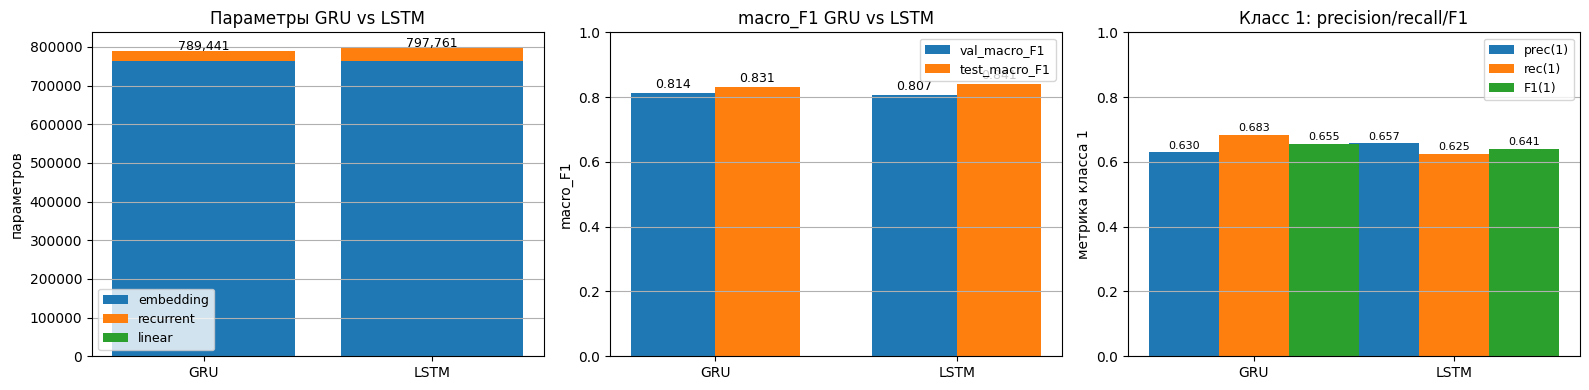

In [ ]:
print(">>> 5.5 (вариант 3): GRU vs LSTM (лучший pos_weight из 5.2)")

best_exp = max(imp_results, key=lambda r: r["v_macro"])
best_pw_name = best_exp["name"]
print(f"Лучший эксперимент из 5.2: {best_pw_name} (val_macro_F1={best_exp['v_macro']:.4f})")

name_to_exp = {e["name"]: e for e in experiments}
best_cfg = name_to_exp[best_pw_name]
print(f"Используем pos_weight={best_cfg['pos_weight']}, dropout={best_cfg['dropout']}, "
      f"lr={best_cfg['lr']}, wd={best_cfg['wd']}")

tr, va, te = make_loaders(L_V5)

def build_model_v5(kind, dropout, hidden_dim=64, emb=64, layers=1):
    if kind == "GRU":
        return GRUFixedLen(len(vocab2index), embedding_dim=emb, hidden_dim=hidden_dim,
                           num_layers=layers, dropout=dropout)
    if kind == "LSTM":
        return LSTMFixedLen(len(vocab2index), embedding_dim=emb, hidden_dim=hidden_dim,
                            num_layers=layers, dropout=dropout)
    raise ValueError(kind)

compare5_results = []
for kind in ["GRU", "LSTM"]:
    print(f"\n>>> {kind} (emb=64, h=64, layers=1, dropout={best_cfg['dropout']}, "
          f"pos_weight={best_cfg['pos_weight']})")
    torch.manual_seed(0); np.random.seed(0)
    model = build_model_v5(kind, dropout=best_cfg["dropout"])
    n_params     = sum(p.numel() for p in model.parameters())
    n_emb_params = model.embeddings.weight.numel()
    n_rec_params = n_params - n_emb_params - model.linear.weight.numel() - model.linear.bias.numel()
    hist, best_macro = train_model_v5(model, tr, va, epochs=20, lr=best_cfg["lr"],
                                       pos_weight=best_cfg["pos_weight"],
                                       weight_decay=best_cfg["wd"],
                                       patience=3, verbose=True)

    v_acc, v_prec, v_rec, v_f1, v_macro, vtp, vfp, vtn, vfn = eval_metrics_full(model, va)
    t_acc, t_prec, t_rec, t_f1, t_macro, ttp, tfp, ttn, tfn = eval_metrics_full(model, te)
    compare5_results.append(dict(
        kind=kind,
        n_params=n_params, n_emb=n_emb_params, n_rec=n_rec_params,
        v_acc=v_acc, v_prec=v_prec, v_rec=v_rec, v_f1=v_f1, v_macro=v_macro,
        t_acc=t_acc, t_prec=t_prec, t_rec=t_rec, t_f1=t_f1, t_macro=t_macro,
        tp=vtp, fp=vfp, tn=vtn, fn=vfn,
        train_loss=hist["train_loss"][-1]
    ))

print("\n\nТаблица (5.5, вариант 3):")
print(f"{'model':<6} | {'params':>8} | {'rec_params':>10} | "
      f"{'val_acc':>8} | {'val_prec1':>9} | {'val_rec1':>8} | {'val_F1_1':>8} | {'val_mac':>7} | "
      f"{'test_acc':>8} | {'test_F1_1':>9} | {'test_mac':>8}")
print("-" * 130)
for r in compare5_results:
    print(f"{r['kind']:<6} | {r['n_params']:>8} | {r['n_rec']:>10} | "
          f"{r['v_acc']:>8.4f} | {r['v_prec']:>9.4f} | {r['v_rec']:>8.4f} | "
          f"{r['v_f1']:>8.4f} | {r['v_macro']:>7.4f} | "
          f"{r['t_acc']:>8.4f} | {r['t_f1']:>9.4f} | {r['t_macro']:>8.4f}")

gru_r  = next(r for r in compare5_results if r["kind"] == "GRU")
lstm_r = next(r for r in compare5_results if r["kind"] == "LSTM")

print(f"\nРазница (GRU − LSTM):")
print(f"  все параметры:      {gru_r['n_params'] - lstm_r['n_params']:+d} "
      f"({100*(gru_r['n_params']/lstm_r['n_params'] - 1):+.1f}%)")
print(f"  рекуррентный слой:  {gru_r['n_rec'] - lstm_r['n_rec']:+d} "
      f"({100*(gru_r['n_rec']/lstm_r['n_rec'] - 1):+.1f}%)")
print(f"  val_acc:            {gru_r['v_acc'] - lstm_r['v_acc']:+.4f}")
print(f"  val_prec(1):        {gru_r['v_prec'] - lstm_r['v_prec']:+.4f}")
print(f"  val_rec(1):         {gru_r['v_rec'] - lstm_r['v_rec']:+.4f}")
print(f"  val_F1(1):          {gru_r['v_f1'] - lstm_r['v_f1']:+.4f}")
print(f"  val_macro_F1:       {gru_r['v_macro'] - lstm_r['v_macro']:+.4f}")
print(f"  test_acc:           {gru_r['t_acc'] - lstm_r['t_acc']:+.4f}")
print(f"  test_F1(1):         {gru_r['t_f1'] - lstm_r['t_f1']:+.4f}")
print(f"  test_macro_F1:      {gru_r['t_macro'] - lstm_r['t_macro']:+.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

kinds = [r["kind"] for r in compare5_results]
p_emb = [r["n_emb"] for r in compare5_results]
p_rec = [r["n_rec"] for r in compare5_results]
p_tot = [r["n_params"] for r in compare5_results]
axes[0].bar(kinds, p_emb, label="embedding")
axes[0].bar(kinds, p_rec, bottom=p_emb, label="recurrent")
axes[0].bar(kinds, [t - e - r for t, e, r in zip(p_tot, p_emb, p_rec)],
            bottom=[e + r for e, r in zip(p_emb, p_rec)], label="linear")
for i, t in enumerate(p_tot):
    axes[0].text(i, t + 2000, f"{t:,}", ha="center", fontsize=9)
axes[0].set_ylabel("параметров"); axes[0].set_title("Параметры GRU vs LSTM")
axes[0].legend(fontsize=9); axes[0].grid(True, axis="y")

x = np.arange(len(kinds)); w = 0.35
axes[1].bar(x - w/2, [r["v_macro"] for r in compare5_results], width=w, label="val_macro_F1")
axes[1].bar(x + w/2, [r["t_macro"] for r in compare5_results], width=w, label="test_macro_F1")
for i, r in enumerate(compare5_results):
    axes[1].text(i - w/2, r["v_macro"] + 0.005, f"{r['v_macro']:.3f}",
                 ha="center", va="bottom", fontsize=9)
    axes[1].text(i + w/2, r["t_macro"] + 0.005, f"{r['t_macro']:.3f}",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels(kinds)
axes[1].set_ylabel("macro_F1"); axes[1].set_ylim(0, 1.0)
axes[1].set_title("macro_F1 GRU vs LSTM")
axes[1].legend(fontsize=9); axes[1].grid(True, axis="y")

axes[2].bar(x - w, [r["v_prec"] for r in compare5_results], width=w, label="prec(1)")
axes[2].bar(x,     [r["v_rec"]  for r in compare5_results], width=w, label="rec(1)")
axes[2].bar(x + w, [r["v_f1"]   for r in compare5_results], width=w, label="F1(1)")
for i, r in enumerate(compare5_results):
    axes[2].text(i - w, r["v_prec"] + 0.005, f"{r['v_prec']:.3f}",
                 ha="center", va="bottom", fontsize=8)
    axes[2].text(i,     r["v_rec"]  + 0.005, f"{r['v_rec']:.3f}",
                 ha="center", va="bottom", fontsize=8)
    axes[2].text(i + w, r["v_f1"]   + 0.005, f"{r['v_f1']:.3f}",
                 ha="center", va="bottom", fontsize=8)
axes[2].set_xticks(x); axes[2].set_xticklabels(kinds)
axes[2].set_ylabel("метрика класса 1"); axes[2].set_ylim(0, 1.0)
axes[2].set_title("Класс 1: precision/recall/F1")
axes[2].legend(fontsize=9); axes[2].grid(True, axis="y")
plt.tight_layout(); plt.show()

GRU и LSTM эквивалентны по качеству на этой задаче, и выбор между ними определяется практическими соображениями, а не метриками. Для практики предпочтительнее GRU: эквивалентное LSTM качество, меньше параметров в рекуррентной части, быстрее обучение.